# Dự án DAP391m – Phân tích chất lượng dinh dưỡng và phân loại thực phẩm đóng gói 
**File tổng hợp từ EDA đến kết luận.** Chạy lần lượt từ trên xuống dưới (Kernel → Restart & Run All).

| Phần | Nội dung |
|---|---|
| 1 | EDA – phân tích khám phá dữ liệu đã làm sạch |
| 2 | Xây nhãn FSA, feature engineering, chia train/test 80/20, chọn đặc trưng |
| 3 | Huấn luyện Logistic Regression, Random Forest và K-Means |
| 4 | Đánh giá: Accuracy, Precision, Recall, F1, Confusion Matrix, ROC-AUC, Feature Importance, so sánh K-Means với nhãn FSA (Crosstab, Heatmap, ARI, NMI), so sánh hai mô hình (Macro/Weighted F1) |
| 5 | Kết luận, trả lời RQ1–RQ7, khuyến nghị và hạn chế |

**Điều kiện chạy:** chạy `Lam_sach.py` trước để có `cleaned_dataset.csv` và `cleaning_report.csv`, rồi đặt hai file này cùng thư mục với file này. Các phần trao đổi dữ liệu qua file CSV trong cùng thư mục (`train.csv`, `test.csv`, `feature_dataset.csv`, `cv_results.csv`, `test_metrics.csv`...), nên phải chạy theo đúng thứ tự.


# Phần 1 – EDA – Phân tích khám phá dữ liệu thực phẩm Open Food Facts (Nhóm 4, DAP391m)

Phần này phân tích bộ dữ liệu sạch `cleaned_dataset.csv` (**7.999 sản phẩm**, 4 danh mục: `beverages`, `dairies`, `meals`, `snacks`; 5 quốc gia: Pháp, Đức, Bỉ, Tây Ban Nha, Anh). File này được tạo bởi `Lam_sach.py`.

**Câu hỏi nghiên cứu được trả lời ở bước EDA** (theo kế hoạch dự án):
| RQ | Nội dung | Mục |
|---|---|---|
| RQ1 | Phân bố chất dinh dưỡng giữa các danh mục | 2, 3, 4 |
| RQ2 | Tương quan đường – béo bão hòa – năng lượng | 5 |
| RQ3 | Tỷ lệ Nutri-Score A/B giữa các quốc gia | 6 |
| RQ4 | Yếu tố dinh dưỡng liên quan nhất tới điểm Nutri-Score (sơ bộ, mô hình ML sẽ kết luận sau) | 5 |
| RQ6 | NOVA và số phụ gia | 7 |

RQ5 (dự đoán bằng ML) và RQ7 (khuyến nghị) thuộc các bước sau.

**Biến chính:** `*_100g` là hàm lượng trên 100 g (đồ uống: trên 100 ml); `nutriscore_grade` (A–E) và `nutriscore_score` (càng thấp càng tốt); `nova_group` (1 ít chế biến → 4 siêu chế biến); `additives_n` (số phụ gia).

## 0. Import thư viện

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. Đọc dữ liệu và kiểm tra giá trị thiếu

In [2]:
df = pd.read_csv("cleaned_dataset.csv", dtype={"code": str})

NUTRI = ["energy-kcal_100g", "fat_100g", "saturated-fat_100g", "sugars_100g", "salt_100g", "proteins_100g"]
CATS = ["beverages", "dairies", "meals", "snacks"]
GRADES = ["A", "B", "C", "D", "E"]

print("Kích thước:", df.shape)
print("Số sản phẩm / danh mục:")
print(df["main_category"].value_counts())

Kích thước: (7999, 32)
Số sản phẩm / danh mục:
main_category
dairies      2214
snacks       2202
meals        2166
beverages    1417
Name: count, dtype: int64


### Tổng quan dữ liệu sau làm sạch
Xem nhanh 5 dòng đầu, kích thước, tên cột và kiểu dữ liệu trước khi đi vào phân tích.

In [3]:
# 5 dòng đầu
df.head()

,code,product_name,brands,brand_main,main_category,categories,n_categories,countries,n_countries,n_selected_countries,country_single,country_france,country_germany,country_belgium,country_spain,...,fat_100g,saturated-fat_100g,sugars_100g,salt_100g,proteins_100g,fiber_100g,additives_n,serving_size,serving_value,serving_unit,nutriscore_grade,nutriscore_score,nova_group,n_stat_outlier_flags,has_fiber
0,6111035000430,Sidi Ali,سيدي علي,سيدي علي,beverages,beverages-and-beverages-preparations; beverage...,7,canada; france; morocco; united-kingdom; unite...,5,2,NaN,True,False,False,False,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,1l,1000.0,ml,A,0.0,NaN,0,True
1,6111252421568,اكوافينا,AQUAFINA,Aquafina,beverages,beverages-and-beverages-preparations; beverage...,6,france; morocco; united-states,3,1,france,True,False,False,False,...,0.0,0.0,0.0,0.000508,0.0,0.0,0.0,1l,1000.0,ml,A,0.0,NaN,0,True
2,6111035502828,Eau minéral naturelle,Ain atlas,Ain atlas,beverages,beverages-and-beverages-preparations; beverage...,6,france; morocco; united-states,3,1,france,True,False,False,False,...,0.0,0.0,0.0,0.120000,0.0,0.0,0.0,NaN,NaN,NaN,A,0.0,NaN,0,True
3,5449000054227,Coca-Cola Original Taste,"COCA-COLA SERVICES SA/NV, Coca-Cola",COCA-COLA SERVICES SA/NV,beverages,beverages-and-beverages-preparations; beverage...,8,algeria; armenia; austria; azerbaijan; belarus...,31,5,NaN,True,True,True,True,...,0.0,0.0,10.6,0.000000,0.0,0.0,3.0,250 ml,250.0,ml,E,12.0,4.0,0,True
4,5449000147417,Cappy PULPY,Cappy,Cappy,beverages,beverages-and-beverages-preparations; plant-ba...,8,bulgaria; france; georgia; moldova; morocco; t...,7,1,france,True,False,False,False,...,0.0,0.0,4.4,0.040000,0.0,NaN,0.0,NaN,NaN,NaN,C,4.0,4.0,0,False


In [4]:
# Kích thước, tên cột và kiểu dữ liệu
print("Kích thước (dòng, cột):", df.shape)
print("\nTên cột:")
print(list(df.columns))
print("\nKiểu dữ liệu:")
print(df.dtypes.to_string())

Kích thước (dòng, cột): (7999, 32)

Tên cột:
['code', 'product_name', 'brands', 'brand_main', 'main_category', 'categories', 'n_categories', 'countries', 'n_countries', 'n_selected_countries', 'country_single', 'country_france', 'country_germany', 'country_belgium', 'country_spain', 'country_united-kingdom', 'energy-kcal_100g', 'fat_100g', 'saturated-fat_100g', 'sugars_100g', 'salt_100g', 'proteins_100g', 'fiber_100g', 'additives_n', 'serving_size', 'serving_value', 'serving_unit', 'nutriscore_grade', 'nutriscore_score', 'nova_group', 'n_stat_outlier_flags', 'has_fiber']

Kiểu dữ liệu:
code                          str
product_name                  str
brands                        str
brand_main                    str
main_category                 str
categories                    str
n_categories                int64
countries                     str
n_countries                 int64
n_selected_countries        int64
country_single                str
country_france               bool

In [5]:
# Tỷ lệ thiếu của các cột phân tích (%)
cols = NUTRI + ["fiber_100g", "additives_n", "nutriscore_grade", "nutriscore_score", "nova_group"]
miss = (df[cols].isna().mean() * 100).round(1)
print(miss.to_string())

# Thiếu Nutri-Score / NOVA theo danh mục (%)
print()
print(df.groupby("main_category")[["nutriscore_grade", "nova_group", "additives_n"]].apply(lambda x: x.isna().mean() * 100).round(1))

energy-kcal_100g       0.0
fat_100g               0.0
saturated-fat_100g     0.0
sugars_100g            0.0
salt_100g              0.0
proteins_100g          0.0
fiber_100g            30.6
additives_n            5.2
nutriscore_grade       4.9
nutriscore_score       4.9
nova_group            10.1

               nutriscore_grade  nova_group  additives_n
main_category                                           
beverages                  12.1        13.0          5.8
dairies                     0.9        12.0          4.3
meals                       5.5        12.5          9.3
snacks                      3.5         4.0          1.8


**Nhận xét:**
- 6 chỉ số trọng yếu (năng lượng, béo, béo bão hòa, đường, muối, đạm) **không còn thiếu** vì đã lọc ở bước làm sạch.
- Còn thiếu: chất xơ 30,6%, NOVA 10,1%, phụ gia 5,2%, Nutri-Score 4,9% (389 sản phẩm). Các sản phẩm thiếu nhãn này chính là nhóm cần dự đoán ở bước ML.
- Đồ uống thiếu Nutri-Score nhiều nhất (12,1%) vì cà phê, trà, nước khoáng... thường được ghi "not-applicable" hoặc "unknown".
- Vì còn thiếu, các phân tích dưới đây chỉ tính trên các dòng có dữ liệu của biến đó; số dòng được ghi rõ khi cần.

## 2. Thống kê mô tả

In [6]:
# describe() cho tất cả thuộc tính số (không gồm cột bool)
stats_all = df.describe().round(2).T
stats_all["count"] = stats_all["count"].astype(int)
stats_all

,count,mean,std,min,25%,50%,75%,max
n_categories,7999,8.31,3.54,1.00,6.0,8.00,10.0,31.0
n_countries,7999,2.28,1.89,1.00,1.0,2.00,3.0,31.0
n_selected_countries,7999,1.54,0.75,1.00,1.0,1.00,2.0,5.0
energy-kcal_100g,7999,234.39,192.84,0.00,62.0,166.00,405.0,898.0
fat_100g,7999,12.33,15.05,0.00,1.5,6.20,20.0,99.8
saturated-fat_100g,7999,5.83,9.23,0.00,0.3,2.00,7.2,66.9
sugars_100g,7999,9.85,14.65,0.00,1.5,3.80,10.7,97.0
salt_100g,7999,0.67,1.45,0.00,0.1,0.43,0.9,54.8
proteins_100g,7999,6.67,6.67,0.00,2.2,5.50,8.8,79.0
fiber_100g,5549,2.68,3.76,0.00,0.2,1.50,3.7,40.0


**Lưu ý khi đọc:** `describe()` trộn cả bốn danh mục, mà đồ uống tính trên 100 ml còn ba nhóm kia trên 100 g. Các cột `serving_value`, `n_categories`, `n_countries`, `n_selected_countries`, `n_stat_outlier_flags` là thông tin mô tả/cờ kiểm tra, không phải chỉ số dinh dưỡng.

In [7]:
# Thống kê mô tả toàn bộ dữ liệu
stats_nutri = df[NUTRI + ["fiber_100g", "additives_n"]].describe().round(2).T
stats_nutri["count"] = stats_nutri["count"].astype(int)
print(stats_nutri)

                    count    mean     std  min   25%     50%    75%    max
energy-kcal_100g     7999  234.39  192.84  0.0  62.0  166.00  405.0  898.0
fat_100g             7999   12.33   15.05  0.0   1.5    6.20   20.0   99.8
saturated-fat_100g   7999    5.83    9.23  0.0   0.3    2.00    7.2   66.9
sugars_100g          7999    9.85   14.65  0.0   1.5    3.80   10.7   97.0
salt_100g            7999    0.67    1.45  0.0   0.1    0.43    0.9   54.8
proteins_100g        7999    6.67    6.67  0.0   2.2    5.50    8.8   79.0
fiber_100g           5549    2.68    3.76  0.0   0.2    1.50    3.7   40.0
additives_n          7580    1.59    2.18  0.0   0.0    1.00    2.0   19.0


In [8]:
# Tỷ lệ Nutri-Score theo danh mục (%), chỉ tính sản phẩm CÓ nhãn
known = df.dropna(subset=["nutriscore_grade"])
ct = pd.crosstab(known["main_category"], known["nutriscore_grade"], normalize="index") * 100
ct["A+B"] = ct["A"] + ct["B"]
print(ct.round(1))
print()
print("Số sản phẩm có nhãn:", known["main_category"].value_counts().to_dict())

nutriscore_grade     A     B     C     D     E   A+B
main_category                                       
beverages          7.9  18.5  33.8  17.7  22.0  26.5
dairies           15.7  14.8  27.7  30.0  11.8  30.5
meals             17.9  22.4  44.2  13.7   1.9  40.3
snacks             3.5   3.0  15.7  28.6  49.2   6.5

Số sản phẩm có nhãn: {'dairies': 2193, 'snacks': 2124, 'meals': 2047, 'beverages': 1246}


**Nhận xét (RQ1):**
- **Snacks** kém nhất: gần một nửa hạng E (49,2%), chỉ 6,5% đạt A/B.
- **Meals** tốt nhất: 40,3% đạt A/B, hạng C chiếm 44,2%, hạng E rất ít (1,9%).
- **Dairies** phân hóa: C (27,7%) và D (30,0%) chiếm phần lớn, A/B đạt 30,5%.
- **Beverages**: A/B 26,5%, nhưng hạng E cũng tới 22,0%. Lưu ý Nutri-Score của đồ uống dùng bảng điểm riêng nên không hoàn toàn so sánh được với thực phẩm rắn.
- Đã loại sản phẩm chưa có nhãn khỏi mẫu số (bản trước gộp vào "UNKNOWN" nên tỷ lệ bị loãng).

In [9]:
# Trung bình và trung vị các chỉ số theo danh mục
vars_ = NUTRI + ["additives_n"]
print("--- TRUNG BÌNH ---")
print(df.groupby("main_category")[vars_].mean().round(2).T)
print("\n--- TRUNG VỊ ---")
print(df.groupby("main_category")[vars_].median().round(2).T)

--- TRUNG BÌNH ---
main_category       beverages  dairies   meals  snacks
energy-kcal_100g        55.80   201.74  149.82  465.34
fat_100g                 1.33    15.86    5.63   22.44
saturated-fat_100g       0.77    10.34    1.75    8.55
sugars_100g              6.89     4.98    2.70   23.70
salt_100g                0.16     0.63    1.02    0.68
proteins_100g            1.51     8.83    6.18    8.28
additives_n              1.64     0.96    1.41    2.33

--- TRUNG VỊ ---
main_category       beverages  dairies  meals  snacks
energy-kcal_100g        39.00   128.00  134.0  473.00
fat_100g                 0.01     7.90    4.4   22.00
saturated-fat_100g       0.00     5.00    1.0    5.80
sugars_100g              4.10     3.80    2.2   23.00
salt_100g                0.02     0.15    0.8    0.51
proteins_100g            0.22     5.60    5.6    7.00
additives_n              1.00     0.00    0.0    2.00


**Nhận xét:**
- **Snacks** có năng lượng (~465 kcal), đường (23,7 g) và phụ gia (2,33) cao nhất.
- **Dairies** nhiều béo (15,9 g) và béo bão hòa (10,3 g) nhưng ít đường, nên hay bị hạng D.
- **Meals** nhiều muối nhất (1,02 g/100g) dù Nutri-Score tốt.
- **Beverages** năng lượng thấp (~56 kcal) nhưng đường trung bình 6,9 g/100ml.
- Trung vị thấp hơn trung bình ở nhiều chỉ số (vd. béo bão hòa của dairies: trung bình 10,3 vs trung vị 5,0) → dữ liệu **lệch phải**, vì vậy phần kiểm định dùng phương pháp phi tham số.

## 3. Trực quan hóa phân bố theo danh mục (RQ1)

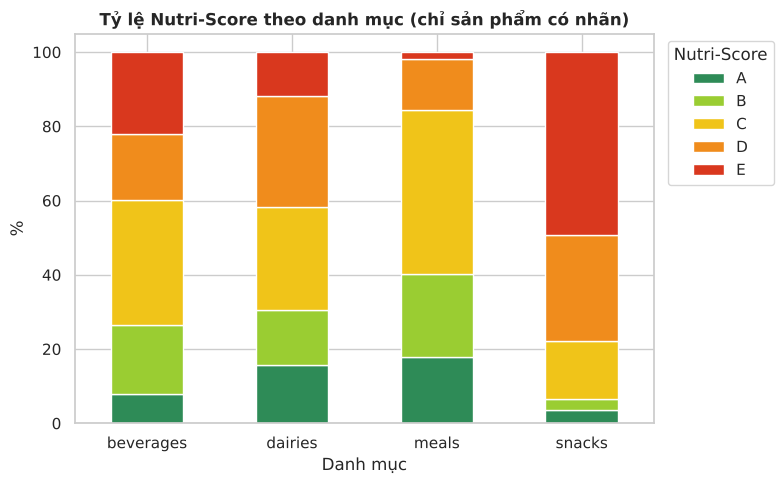

In [10]:
# Biểu đồ 1: Nutri-Score theo danh mục (tỷ lệ %)
ct_plot = ct[GRADES]
colors = ["#2e8b57", "#9acd32", "#f0c419", "#f08c1c", "#d9381e"]
ax = ct_plot.plot(kind="bar", stacked=True, color=colors, figsize=(8, 5), edgecolor="white")
ax.set_title("Tỷ lệ Nutri-Score theo danh mục (chỉ sản phẩm có nhãn)", fontweight="bold")
ax.set_xlabel("Danh mục")
ax.set_ylabel("%")
plt.xticks(rotation=0)
plt.legend(title="Nutri-Score", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("eda_nutriscore_distribution.png", dpi=120)
plt.show()

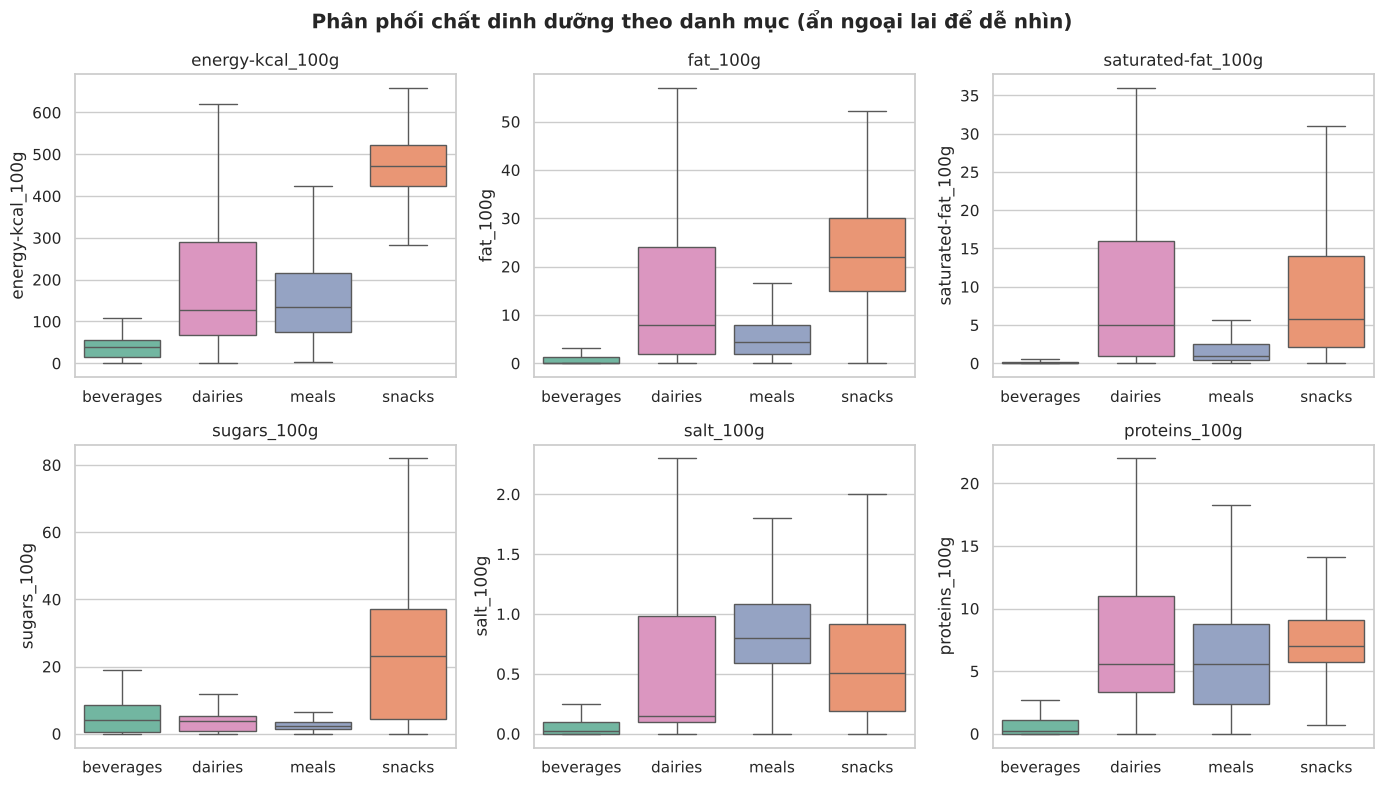

In [11]:
# Biểu đồ 2: Phân phối các chất dinh dưỡng theo danh mục (boxplot)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.ravel(), NUTRI):
    sns.boxplot(data=df, x="main_category", y=c, order=CATS, hue="main_category", legend=False,
                palette="Set2", showfliers=False, ax=ax)
    ax.set_title(c)
    ax.set_xlabel("")
fig.suptitle("Phân phối chất dinh dưỡng theo danh mục (ẩn ngoại lai để dễ nhìn)", fontweight="bold")
plt.tight_layout()
plt.savefig("eda_boxplot_nutrients.png", dpi=120)
plt.show()

**Nhận xét:** biểu đồ cột xếp chồng cho thấy rõ snacks lệch về D–E, meals tập trung ở C và các hạng tốt. Boxplot cho thấy khoảng cách giữa các danh mục lớn nhất ở năng lượng và béo (snacks cao hẳn), muối nổi bật ở meals, đạm thấp ở beverages. Một số chỉ số (béo, béo bão hòa của beverages) gần như bằng 0 nên hộp bị nén sát trục.

### Kiểm định thống kê giữa các danh mục

In [12]:
# Kiểm định Kruskal-Wallis: chỉ số có khác nhau giữa 4 danh mục không? (RQ1)
# Dùng Kruskal-Wallis thay ANOVA vì dữ liệu dinh dưỡng lệch phải, không chuẩn.
rows = []
for c in NUTRI + ["additives_n"]:
    groups = [df.loc[df["main_category"] == k, c].dropna() for k in CATS]
    h, p = stats.kruskal(*groups)
    rows.append({"chi_so": c, "H": round(h, 1), "p_value": p, "khac_biet": "có" if p < 0.05 else "không"})
print(pd.DataFrame(rows).to_string(index=False))

            chi_so      H       p_value khac_biet
  energy-kcal_100g 4956.9  0.000000e+00        có
          fat_100g 3671.4  0.000000e+00        có
saturated-fat_100g 3168.4  0.000000e+00        có
       sugars_100g 1963.3  0.000000e+00        có
         salt_100g 2505.2  0.000000e+00        có
     proteins_100g 2505.8  0.000000e+00        có
       additives_n  676.8 2.274026e-146        có


**Nhận xét:** tất cả chỉ số đều khác biệt có ý nghĩa giữa 4 danh mục (p < 0,001). Khác biệt mạnh nhất ở năng lượng (H ≈ 4.957), yếu nhất ở số phụ gia (H ≈ 677). Dùng Kruskal–Wallis thay cho ANOVA vì dữ liệu lệch, không chuẩn. Với cỡ mẫu ~8.000, p-value gần như luôn nhỏ, nên cần đọc kèm độ lớn khác biệt ở các bảng trên.

## 4. Ngoại lai thống kê

In [13]:
# Ngoại lai thống kê (đã được gắn cờ ở bước làm sạch, KHÔNG xóa)
print("Số chỉ số bị gắn cờ ngoại lai / sản phẩm:")
print(df["n_stat_outlier_flags"].value_counts().sort_index())
print("\nTỷ lệ sản phẩm có >= 1 cờ theo danh mục (%):")
print((df.assign(f=df["n_stat_outlier_flags"] > 0).groupby("main_category")["f"].mean() * 100).round(1))

Số chỉ số bị gắn cờ ngoại lai / sản phẩm:
n_stat_outlier_flags
0    7348
1     472
2     110
3      31
4      21
5      10
6       7
Name: count, dtype: int64

Tỷ lệ sản phẩm có >= 1 cờ theo danh mục (%):
main_category
beverages    22.5
dairies       3.3
meals         5.1
snacks        6.7
Name: f, dtype: float64


**Nhận xét:** 91,9% sản phẩm không bị cờ nào; 8,1% có ít nhất một chỉ số bị gắn cờ (IQR × 3 trong từng danh mục). Beverages có tỷ lệ cờ cao nhất (22,5%) vì nhóm này gồm nhiều loại khác nhau (nước, sữa thực vật, nước sốt, bột pha...), trung vị gần 0 nên ngưỡng IQR rất hẹp. Các giá trị này **không bị xóa** vì phần lớn là sản phẩm có thật; cột `n_stat_outlier_flags` được giữ để dùng khi cần.

## 5. Tương quan và quan hệ giữa các chỉ số (RQ2, RQ4)

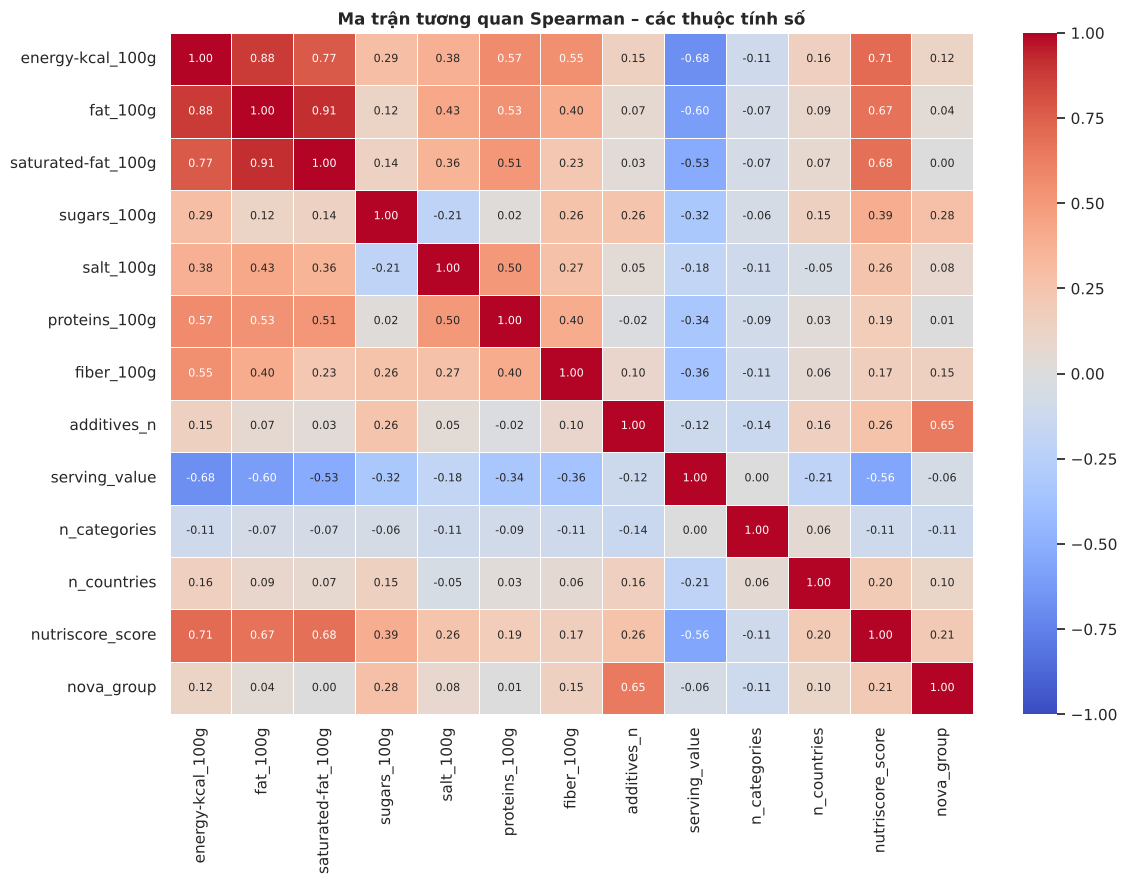

Cặp đặc trưng tương quan cao (|r| >= 0.7):
fat_100g          saturated-fat_100g    0.91
energy-kcal_100g  fat_100g              0.88
                  saturated-fat_100g    0.77


In [14]:
# Ma trận tương quan (Spearman) của các thuộc tính số, dùng để cân nhắc chọn đặc trưng
NUM_COLS = NUTRI + ["fiber_100g", "additives_n", "serving_value", "n_categories", "n_countries",
                    "nutriscore_score", "nova_group"]
corr_all = df[NUM_COLS].corr(method="spearman")   # tính theo từng cặp, bỏ qua giá trị thiếu

plt.figure(figsize=(12, 9))
sns.heatmap(corr_all, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={"size": 8})
plt.title("Ma trận tương quan Spearman – các thuộc tính số", fontweight="bold")
plt.tight_layout()
plt.savefig("eda_correlation_all_numeric.png", dpi=120)
plt.show()

# Các cặp thuộc tính dinh dưỡng có |r| >= 0.7 (nguy cơ đa cộng tuyến khi làm ML)
feat = corr_all.loc[NUTRI + ["fiber_100g", "additives_n"], NUTRI + ["fiber_100g", "additives_n"]]
pairs = (feat.where(np.triu(np.ones(feat.shape, dtype=bool), k=1)).stack()
             .loc[lambda s: s.abs() >= 0.7].sort_values(key=abs, ascending=False).round(2))
print("Cặp đặc trưng tương quan cao (|r| >= 0.7):")
print(pairs.to_string())

**Cách dùng cho bước chọn đặc trưng:** `nutriscore_score` và `nova_group` chỉ để tham chiếu. Nutri-Score được tính từ chính năng lượng, đường, béo bão hòa, muối, đạm, chất xơ, nên tương quan cao với chúng là hiển nhiên và không nên dùng để quyết định giữ/loại đặc trưng. Tiêu chí chọn đặc trưng nên dựa vào quan hệ giữa các đặc trưng với nhau (đa cộng tuyến) và với nhãn độc lập theo WHO/FSA ở bước sau.

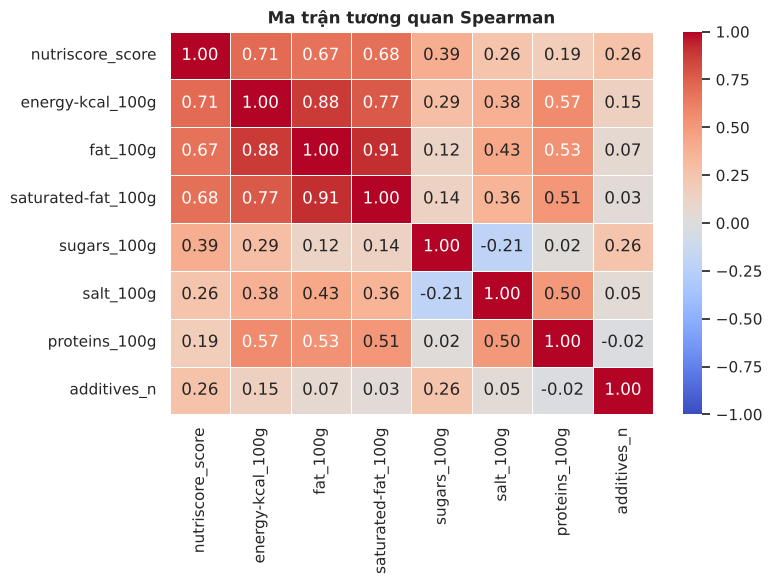

energy-kcal_100g      0.71
saturated-fat_100g    0.68
fat_100g              0.67
sugars_100g           0.39
additives_n           0.26
salt_100g             0.26
proteins_100g         0.19
Name: nutriscore_score, dtype: float64


In [15]:
# Biểu đồ 3: Ma trận tương quan Spearman (RQ2, RQ4)
# Spearman phù hợp hơn Pearson vì dữ liệu lệch và có ngoại lai.
cols = ["nutriscore_score"] + NUTRI + ["additives_n"]
corr = df[cols].corr(method="spearman")
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Ma trận tương quan Spearman", fontweight="bold")
plt.tight_layout()
plt.savefig("eda_correlation_matrix.png", dpi=120)
plt.show()
print(corr["nutriscore_score"].drop("nutriscore_score").sort_values(ascending=False).round(2))

**Nhận xét:**
- Điểm Nutri-Score tương quan thuận mạnh nhất với **năng lượng (0,71)**, **béo bão hòa (0,68)** và **béo (0,67)**; đường ở mức vừa (0,39); muối (0,26), phụ gia (0,26), đạm (0,19) yếu.
- Béo và béo bão hòa tương quan rất cao (0,91), cả hai cũng cao với năng lượng (0,88 và 0,77) → **đa cộng tuyến**, cần cân nhắc khi xây mô hình ML.
- Đường gần như độc lập với béo (0,12) và béo bão hòa (0,14): hai "con đường" riêng làm sản phẩm bị điểm xấu.
- Đây là tương quan đơn biến, chưa kết luận nhân quả; mức độ quan trọng thật sự của từng yếu tố sẽ được trả lời bằng Feature Importance ở bước ML.
- So với bản cũ: dùng Spearman thay Pearson, nên hệ số của đường giảm (0,64 → 0,39).

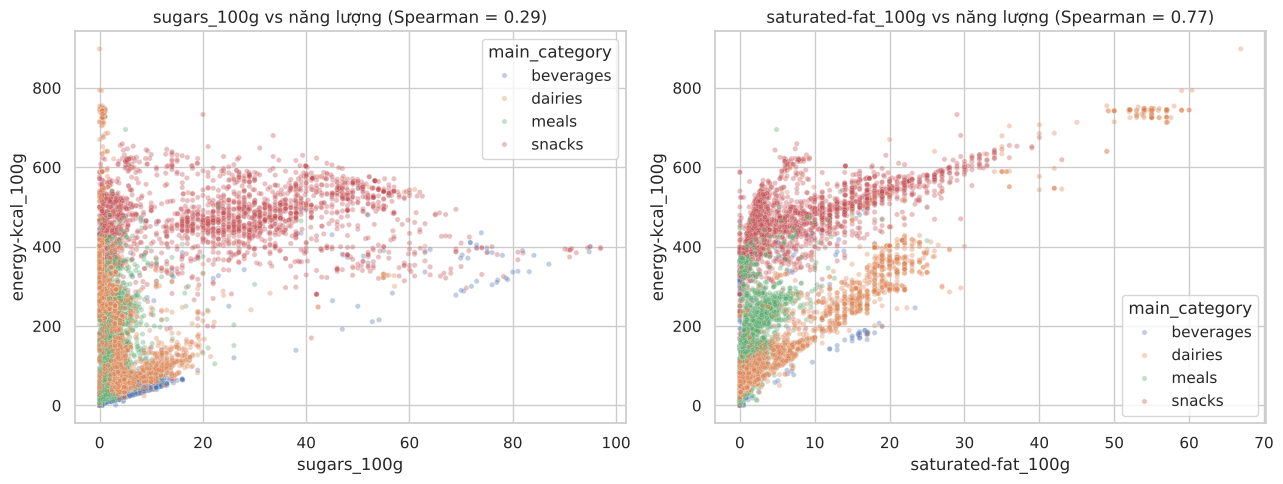

Tương quan đường - béo bão hòa: 0.14


In [16]:
# Biểu đồ 4: Đường / béo bão hòa với năng lượng (RQ2)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, c in zip(axes, ["sugars_100g", "saturated-fat_100g"]):
    sns.scatterplot(data=df, x=c, y="energy-kcal_100g", hue="main_category", hue_order=CATS,
                    alpha=0.35, s=14, ax=ax)
    r, p = stats.spearmanr(df[c], df["energy-kcal_100g"])
    ax.set_title(f"{c} vs năng lượng (Spearman = {r:.2f})")
plt.tight_layout()
plt.savefig("eda_scatter_energy.png", dpi=120)
plt.show()

r, _ = stats.spearmanr(df["sugars_100g"], df["saturated-fat_100g"])
print(f"Tương quan đường - béo bão hòa: {r:.2f}")

**Nhận xét (RQ2):** năng lượng tăng theo béo bão hòa rõ hơn theo đường. Tương quan đường – năng lượng toàn bộ chỉ 0,29 nhưng thay đổi mạnh theo danh mục (beverages 0,68; dairies −0,56, có thể do sữa chua nhiều đường nhưng ít năng lượng còn phô mai nhiều béo nhưng ít đường). Vì chiều tương quan đổi dấu theo nhóm, nên phân tích theo từng danh mục chứ không gộp chung. Đường và béo bão hòa gần như độc lập (0,14).

## 6. So sánh Nutri-Score giữa các quốc gia (RQ3)

In [17]:
# RQ3: Nutri-Score A/B giữa các quốc gia
# Nhiều sản phẩm bán ở nhiều nước nên các nhóm quốc gia bị chồng lấn.
# Để so sánh công bằng, chỉ dùng sản phẩm bán ở ĐÚNG MỘT nước mục tiêu (cột country_single).
print("Sản phẩm bán ở >= 2 nước mục tiêu:", f"{(df['n_selected_countries'] > 1).mean() * 100:.1f}%")

single = df.dropna(subset=["country_single", "nutriscore_grade"]).copy()
single["good"] = single["nutriscore_grade"].isin(["A", "B"])
tab = single.groupby("country_single").agg(n=("good", "size"), ty_le_AB=("good", "mean"))
tab["ty_le_AB"] = (tab["ty_le_AB"] * 100).round(1)
print(tab.sort_values("ty_le_AB", ascending=False))

chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(single["country_single"], single["good"]))
print(f"\nChi-square: chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2g}")

# Cơ cấu danh mục từng nước (để biết khác biệt có do cơ cấu sản phẩm không)
print("\nCơ cấu danh mục theo nước (%):")
print((pd.crosstab(single["country_single"], single["main_category"], normalize="index") * 100).round(1))

Sản phẩm bán ở >= 2 nước mục tiêu: 41.4%
                   n  ty_le_AB
country_single                
united-kingdom   841      33.1
france          1676      31.2
spain            710      26.8
belgium          513      24.6
germany          752      24.5

Chi-square: chi2 = 24.8, dof = 4, p = 5.4e-05

Cơ cấu danh mục theo nước (%):
main_category   beverages  dairies  meals  snacks
country_single                                   
belgium              25.7     32.0   23.8    18.5
france               12.4     35.9   25.4    26.3
germany              15.2     38.6   25.0    21.3
spain                 5.4     26.8   48.0    19.9
united-kingdom       19.1     22.0   39.2    19.6


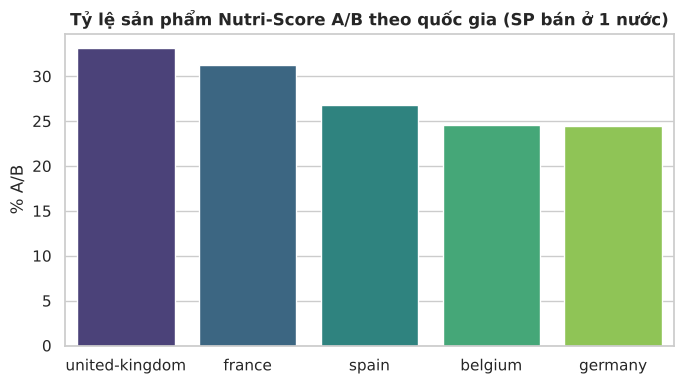

In [18]:
# Biểu đồ 5: Tỷ lệ A/B theo nước
order = tab.sort_values("ty_le_AB", ascending=False).index
plt.figure(figsize=(7, 4))
sns.barplot(x=tab.loc[order].index, y=tab.loc[order, "ty_le_AB"], hue=tab.loc[order].index,
            legend=False, palette="viridis")
plt.title("Tỷ lệ sản phẩm Nutri-Score A/B theo quốc gia (SP bán ở 1 nước)", fontweight="bold")
plt.ylabel("% A/B")
plt.xlabel("")
plt.tight_layout()
plt.savefig("eda_country_ab.png", dpi=120)
plt.show()

In [19]:
# Tỷ lệ A/B theo nước VÀ danh mục (kiểm tra nhiễu do cơ cấu sản phẩm)
print((single.pivot_table(index="country_single", columns="main_category", values="good", aggfunc="mean") * 100).round(1))

main_category   beverages  dairies  meals  snacks
country_single                                   
belgium              31.1     29.3   23.0     9.5
france               30.8     33.1   52.1     8.6
germany              28.9     31.0   29.3     3.8
spain                36.8     41.6   27.9     1.4
united-kingdom       24.2     35.7   49.4     6.1


**Nhận xét:**
- Có 41,4% sản phẩm bán ở từ 2 nước mục tiêu trở lên; nếu tính chồng lấn thì các nhóm quốc gia sẽ giống nhau và so sánh bị sai. Vì vậy chỉ dùng sản phẩm bán ở đúng một nước (n = 4.492 có Nutri-Score).
- Tỷ lệ A/B cao nhất ở Anh (33,1%) và Pháp (31,2%), thấp nhất ở Đức (24,5%) và Bỉ (24,6%). Chi-square có ý nghĩa (p ≈ 5×10⁻⁵), nhưng chênh lệch thực tế chỉ khoảng 8–9 điểm %.
- Cơ cấu danh mục mỗi nước khác nhau (Tây Ban Nha 48% meals, Anh 39% meals, Pháp/Đức nhiều dairies), mà meals có tỷ lệ A/B cao hơn snacks rất nhiều. Bảng theo danh mục cho thấy khác biệt giữa các nước **nhỏ hơn và không đồng đều** khi giữ nguyên danh mục (vd. meals: Pháp 52,1%, Anh 49,4% nhưng Bỉ 23,0%). Vì vậy không nên kết luận một nước "lành mạnh hơn" chỉ từ chênh lệch tổng.
- Mẫu của mỗi nước phụ thuộc vào việc cộng đồng nhập dữ liệu, không đại diện cho toàn thị trường.

## 7. Mức độ chế biến NOVA và phụ gia (RQ6)

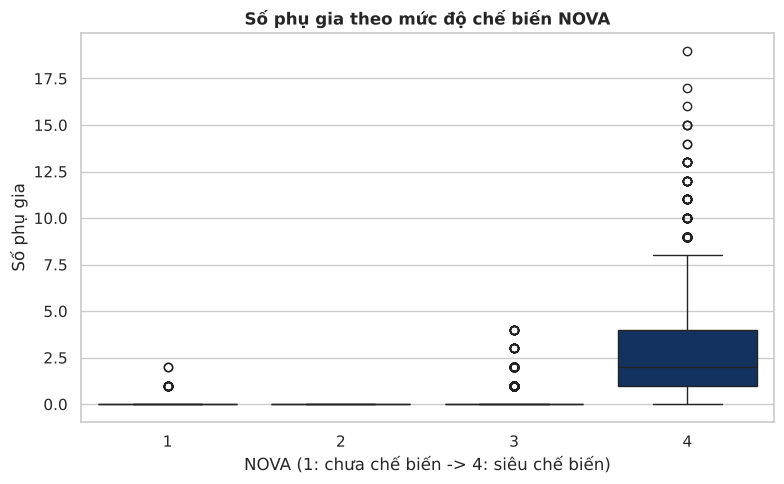

            count  mean  median   max
nova_group                           
1             603  0.04     0.0   2.0
2             113  0.00     0.0   0.0
3            1925  0.25     0.0   4.0
4            4522  2.54     2.0  19.0

Kruskal-Wallis: H = 3033.2, p = 0
Spearman NOVA - phụ gia: r = 0.65, p = 0

Cơ cấu NOVA theo danh mục (%):
nova_group        1    2     3     4
main_category                       
beverages      23.1  0.0  12.5  64.4
dairies        16.2  5.7  33.2  44.8
meals           0.0  0.1  35.7  64.2
snacks          0.4  0.0  21.4  78.2


In [20]:
# Biểu đồ 6 + RQ6: Phụ gia theo NOVA
nova = df.dropna(subset=["nova_group", "additives_n"]).copy()
nova["nova_group"] = nova["nova_group"].astype(int)

plt.figure(figsize=(8, 5))
sns.boxplot(data=nova, x="nova_group", y="additives_n", hue="nova_group", legend=False, palette="Blues")
plt.title("Số phụ gia theo mức độ chế biến NOVA", fontweight="bold")
plt.xlabel("NOVA (1: chưa chế biến -> 4: siêu chế biến)")
plt.ylabel("Số phụ gia")
plt.tight_layout()
plt.savefig("eda_nova_vs_additives.png", dpi=120)
plt.show()

print(nova.groupby("nova_group")["additives_n"].agg(["count", "mean", "median", "max"]).round(2))
h, p = stats.kruskal(*[g["additives_n"] for _, g in nova.groupby("nova_group")])
r, p2 = stats.spearmanr(nova["nova_group"], nova["additives_n"])
print(f"\nKruskal-Wallis: H = {h:.1f}, p = {p:.2g}")
print(f"Spearman NOVA - phụ gia: r = {r:.2f}, p = {p2:.2g}")
print("\nCơ cấu NOVA theo danh mục (%):")
print((pd.crosstab(nova["main_category"], nova["nova_group"], normalize="index") * 100).round(1))

**Nhận xét:**
- Phụ gia tăng mạnh theo NOVA: trung bình 0,04 (NOVA 1), 0 (NOVA 2), 0,25 (NOVA 3) và **2,54 (NOVA 4)**. Kruskal–Wallis và Spearman (r = 0,65) đều có ý nghĩa.
- NOVA 1–3 gần như tập trung ở 0 phụ gia nên hộp bị nén sát trục; NOVA 4 trải rộng, trung vị 2, tối đa 19.
- NOVA 2 chỉ có 113 sản phẩm (đều 0 phụ gia) nên cần thận trọng khi diễn giải.
- NOVA 4 chiếm 62,9% sản phẩm có NOVA (4.522/7.192), cao nhất ở snacks (78,2%); meals gần như không có NOVA 1.
- Phụ gia là thành phần dùng để xác định NOVA 4, nên mối liên hệ này một phần mang tính định nghĩa, không hoàn toàn là phát hiện độc lập.

## 8. Kết luận
1. **Snacks** kém lành mạnh nhất: năng lượng, đường, phụ gia cao nhất; 49,2% hạng E, 78,2% siêu chế biến.
2. **Meals** có Nutri-Score tốt nhất (A/B 40,3%) nhưng muối cao nhất (1,02 g/100g).
3. **Dairies** bị kéo điểm xuống chủ yếu do béo/béo bão hòa chứ không phải đường.
4. **Beverages** không đồng nhất, nhiều giá trị thiếu nhãn (12,1%) và đường lỏng đáng kể (6,9 g/100ml).
5. Điểm Nutri-Score liên quan mạnh nhất tới **năng lượng, béo bão hòa, béo**, rồi đường; muối, đạm, phụ gia yếu hơn (RQ4 sơ bộ).
6. Khác biệt giữa quốc gia có ý nghĩa thống kê nhưng nhỏ và chịu ảnh hưởng của cơ cấu danh mục (RQ3).
7. Phụ gia gắn chặt với NOVA 4 (RQ6).

**Hạn chế và bước tiếp theo**
- Còn 389 sản phẩm thiếu Nutri-Score, 807 thiếu NOVA, 30,6% thiếu chất xơ.
- Một số cặp (hạng, điểm) Nutri-Score không khớp hoàn toàn (dữ liệu cộng đồng lẫn cách tính cũ và mới; đồ uống dùng bảng điểm riêng).
- Béo, béo bão hòa và năng lượng đa cộng tuyến; khi làm ML (RQ5) cần chú ý, và không dùng `nutriscore_score`, `nova_group` làm feature để tránh rò rỉ nhãn.

# Phần 2 – Xây dựng nhãn, Feature Engineering và Lựa chọn đặc trưng (Feature Selection)

**Mục tiêu:** từ `cleaned_dataset.csv` (7.999 sản phẩm) tạo bộ dữ liệu sẵn sàng cho mô hình:
1. Xây nhãn 3 mức **Healthy / Moderate / Less Healthy** *độc lập với Nutri-Score* (dựa trên ngưỡng "đèn giao thông" của FSA – Anh).
2. Tạo các biến phái sinh.
3. Khai báo bộ đặc trưng và **kiểm soát rò rỉ dữ liệu**.
4. **Chia train/test 80/20** (phân tầng theo nhãn và danh mục).
5. Kiểm tra và chọn đặc trưng **chỉ trên tập train**.
6. Lưu `train.csv`, `test.csv` (và `feature_dataset.csv` đầy đủ) cho Phần 3 (huấn luyện mô hình).

**Về rò rỉ dữ liệu (quan trọng):** nhãn của nhóm được tính từ 4 chất (béo, béo bão hòa, đường, muối). Nếu đưa chính 4 chất đó vào làm đặc trưng thì mô hình chỉ học lại công thức tính nhãn, độ chính xác cao nhưng vô nghĩa. Vì vậy bộ đặc trưng **không chứa 4 chất tạo nhãn** (cũng không chứa biến suy ra từ chúng). `nutriscore_grade`, `nutriscore_score`, `nova_group` cũng không bao giờ được dùng làm đặc trưn

## 1. Đọc dữ liệu

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEED = 42
df = pd.read_csv("cleaned_dataset.csv", dtype={"code": str})
print(df.shape)
print(df["main_category"].value_counts())

(7999, 32)
main_category
dairies      2214
snacks       2202
meals        2166
beverages    1417
Name: count, dtype: int64


## 2. Xây nhãn chất lượng dinh dưỡng (độc lập với Nutri-Score)

Dùng ngưỡng nhãn đèn giao thông của FSA (Anh) cho 4 chất: **béo, béo bão hòa, đường, muối**. Thực phẩm tính trên 100 g, **đồ uống có ngưỡng riêng** (tính trên 100 ml, nghiêm hơn).

#### 1. Ngưỡng đánh giá FSA (`thực phẩm / đồ uống`)
| Chất dinh dưỡng | Ngưỡng Thấp (≤) / Cao (>) cho Thực phẩm | Ngưỡng Thấp (≤) / Cao (>) cho Đồ uống |
| :--- | :--- | :--- |
| **Béo (`fat_100g`)** | 3.0 g / 17.5 g | 1.5 g / 8.75 g |
| **Béo bão hòa (`saturated-fat_100g`)** | 1.5 g / 5.0 g | 0.75 g / 2.5 g |
| **Đường (`sugars_100g`)** | 5.0 g / 22.5 g | 2.5 g / 11.25 g |
| **Muối (`salt_100g`)** | 0.3 g / 1.5 g | 0.3 g / 0.75 g |

#### 2. Quy tắc tính điểm & Đếm số ô đỏ (`n_red`)
* **Điểm từng chất:** Thấp ($\le$ low) = 0đ | Trung bình = 1đ | Cao (> high) = 2đ.
* **Tổng điểm FSA (`fsa_points`):** Tổng điểm của 4 chất (0 – 8 điểm).
* **Số ô đỏ (`n_red`):** Số lượng chất đạt mức "Cao" (điểm = 2).

#### 3. Quy tắc chọn nhãn phân loại (`health_label`)
* **Less Healthy:** Khi có $\ge 2$ chất đạt mức cao (`n_red >= 2`) HOẶC tổng điểm FSA từ 5 trở lên (`p >= 5`).
* **Healthy:** Khi không có chất nào đạt mức cao (`r == 0`) VÀ tổng điểm FSA từ 2 trở xuống (`p <= 2`).
* **Moderate:** Các trường hợp còn lại (Điểm và số ô đỏ ở mức trung gian).



In [22]:
# (thấp, cao) cho thực phẩm và đồ uống
FSA = {
    "fat_100g":           {"food": (3.0, 17.5), "drink": (1.5, 8.75)},
    "saturated-fat_100g": {"food": (1.5, 5.0),  "drink": (0.75, 2.5)},
    "sugars_100g":        {"food": (5.0, 22.5), "drink": (2.5, 11.25)},
    "salt_100g":          {"food": (0.3, 1.5),  "drink": (0.3, 0.75)},
}
LABEL_NUTRIENTS = list(FSA)
is_drink = df["main_category"] == "beverages"

fsa_points = pd.DataFrame(index=df.index)
for col, th in FSA.items():
    low = np.where(is_drink, th["drink"][0], th["food"][0])
    high = np.where(is_drink, th["drink"][1], th["food"][1])
    fsa_points[col] = np.where(df[col] > high, 2, np.where(df[col] > low, 1, 0))

df["fsa_points"] = fsa_points.sum(axis=1)
df["n_red"] = (fsa_points == 2).sum(axis=1)

# Quy tắc chọn nhãn (xem bảng quy tắc ở trên)
def to_label(row):
    p = row["fsa_points"]
    r = row["n_red"]
    if r >= 2 or p >= 5:
        return "Less Healthy"
    if r == 0 and p <= 2:
        return "Healthy"
    return "Moderate"

df["health_label"] = df.apply(to_label, axis=1)
LABELS = ["Healthy", "Moderate", "Less Healthy"]

print("Phân bố nhãn:")
print(df["health_label"].value_counts().reindex(LABELS))
print("\nTỷ lệ (%):")
print((df["health_label"].value_counts(normalize=True).reindex(LABELS) * 100).round(1))

Phân bố nhãn:
health_label
Healthy         3435
Moderate        2110
Less Healthy    2454
Name: count, dtype: int64

Tỷ lệ (%):
health_label
Healthy         42.9
Moderate        26.4
Less Healthy    30.7
Name: proportion, dtype: float64


health_label   Healthy  Moderate  Less Healthy
main_category                                 
beverages         80.5      14.4           5.2
dairies           41.1      19.4          39.5
meals             56.1      40.1           3.8
snacks             7.7      27.7          64.7


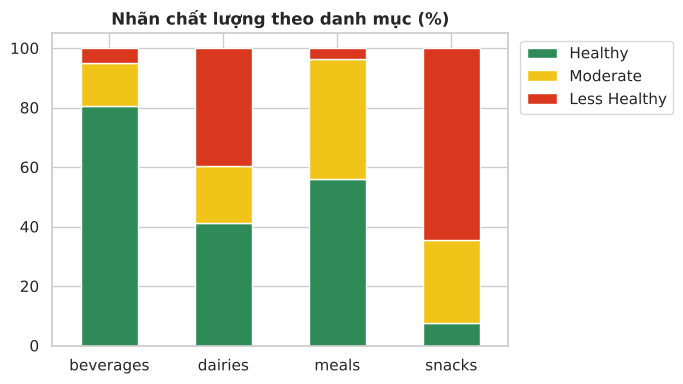

In [23]:
# Nhãn theo danh mục
ct = (pd.crosstab(df["main_category"], df["health_label"], normalize="index")[LABELS] * 100).round(1)
print(ct)
ct.plot(kind="bar", stacked=True, color=["#2e8b57", "#f0c419", "#d9381e"], figsize=(7, 4), edgecolor="white")
plt.title("Nhãn chất lượng theo danh mục (%)", fontweight="bold")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("fe_label_by_category.png", dpi=120)
plt.show()

### Nhãn mới có độc lập với Nutri-Score không?
Nutri-Score dùng thêm năng lượng, đạm, chất xơ, trái cây/rau; nhãn FSA ở đây không dùng. Ta đối chiếu bằng cách gộp Nutri-Score: A,B → Healthy; C → Moderate; D,E → Less Healthy. Hai nhãn nên **tương quan nhưng không trùng**.

In [24]:
known = df.dropna(subset=["nutriscore_grade"]).copy()
known["nutri_3"] = known["nutriscore_grade"].map({"A": "Healthy", "B": "Healthy", "C": "Moderate", "D": "Less Healthy", "E": "Less Healthy"})
print("Tỷ lệ trùng khớp nhãn FSA và Nutri-Score gộp:", round((known["nutri_3"] == known["health_label"]).mean() * 100, 1), "%")
print("\nHàng: Nutri-Score gốc, cột: nhãn FSA (%)")
print((pd.crosstab(known["nutriscore_grade"], known["health_label"], normalize="index")[LABELS] * 100).round(1))

Tỷ lệ trùng khớp nhãn FSA và Nutri-Score gộp: 65.0 %

Hàng: Nutri-Score gốc, cột: nhãn FSA (%)
health_label      Healthy  Moderate  Less Healthy
nutriscore_grade                                 
A                    92.3       6.1           1.6
B                    87.2      12.2           0.6
C                    47.6      45.0           7.4
D                    13.4      34.0          52.7
E                    10.6      12.4          77.0


**Nhận xét:** hai nhãn cùng chiều (A,B phần lớn là Healthy; E phần lớn là Less Healthy) nhưng không trùng hoàn toàn (khoảng 65% khớp, xem kết quả phía trên). Nhãn FSA chỉ nhìn 4 chất cần hạn chế nên không "thưởng" cho chất xơ/đạm như Nutri-Score; do đó đây là nhãn độc lập, có thể dùng để kiểm chứng chéo với Nutri-Score ở Phần 4.

## 3. Tạo biến phát sinh
- `protein_energy_share`: % năng lượng đến từ đạm
- `has_fiber`: có khai báo chất xơ hay không
- Danh mục `main_category` được mã hóa one-hot ở bước mô hình

In [25]:
en = df["energy-kcal_100g"].replace(0, np.nan)   # năng lượng 0 (nước lọc...) -> chia ra NaN, gán 0 bên dưới

df["protein_energy_share"] = (df["proteins_100g"] * 4 / en * 100).clip(0, 100).fillna(0)
df["has_fiber"] = df["fiber_100g"].notna().astype(int)

stats = df[["protein_energy_share", "has_fiber"]].describe().round(2).T
stats["count"] = stats["count"].astype(int)
print(stats)

                      count   mean    std  min   25%    50%    75%    max
protein_energy_share   7999  15.40  15.28  0.0  5.25  10.59  21.11  100.0
has_fiber              7999   0.69   0.46  0.0  0.00   1.00   1.00    1.0


## 4. Khai báo đặc trưng ứng viên và kiểm soát rò rỉ

In [26]:
# Bộ đặc trưng: KHÔNG chứa 4 chất tạo nhãn (béo, béo bão hòa, đường, muối) hay biến suy ra từ chúng
FEATURES = ["energy-kcal_100g", "proteins_100g", "fiber_100g", "additives_n", "protein_energy_share", "has_fiber"]
# Tuyệt đối không dùng làm feature:
FORBIDDEN = ["nutriscore_grade", "nutriscore_score", "nova_group", "fsa_points", "n_red", "health_label"]

assert not set(FORBIDDEN) & set(FEATURES)
assert not set(LABEL_NUTRIENTS) & set(FEATURES)
print("Đặc trưng :", FEATURES)
print("Loại (tạo nhãn):", LABEL_NUTRIENTS)
print("Cấm       :", FORBIDDEN)

Đặc trưng : ['energy-kcal_100g', 'proteins_100g', 'fiber_100g', 'additives_n', 'protein_energy_share', 'has_fiber']
Loại (tạo nhãn): ['fat_100g', 'saturated-fat_100g', 'sugars_100g', 'salt_100g']
Cấm       : ['nutriscore_grade', 'nutriscore_score', 'nova_group', 'fsa_points', 'n_red', 'health_label']


## 5. Chia train / test (80/20)
Chia **trước** khi kiểm tra và chọn đặc trưng, để tập test không tham gia vào bất kỳ quyết định nào. Tỷ lệ 80/20, phân tầng theo nhãn + danh mục để hai tập giữ cùng cơ cấu. Việc điền thiếu và chuẩn hóa nằm trong pipeline ở Phần 3 và chỉ học trên train.

In [27]:
strat = df["health_label"] + "|" + df["main_category"]
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=SEED, stratify=strat)
df["split"] = "train"
df.loc[test_idx, "split"] = "test"
train = df[df["split"] == "train"].copy()

print(df["split"].value_counts())
print("\nNhãn (%) theo tập:")
print((pd.crosstab(df["split"], df["health_label"], normalize="index")[LABELS] * 100).round(1))
print("\nDanh mục (%) theo tập:")
print((pd.crosstab(df["split"], df["main_category"], normalize="index") * 100).round(1))
print("\nTrùng mã vạch giữa train và test:", len(set(train["code"]) & set(df.loc[df.split == "test", "code"])))

split
train    6399
test     1600
Name: count, dtype: int64

Nhãn (%) theo tập:
health_label  Healthy  Moderate  Less Healthy
split                                        
test             42.9      26.4          30.6
train            42.9      26.4          30.7

Danh mục (%) theo tập:
main_category  beverages  dairies  meals  snacks
split                                           
test                17.7     27.7   27.1    27.6
train               17.7     27.7   27.1    27.5

Trùng mã vạch giữa train và test: 0


## 6. Kiểm tra các đặc trưng đã chọn (chỉ trên tập train)

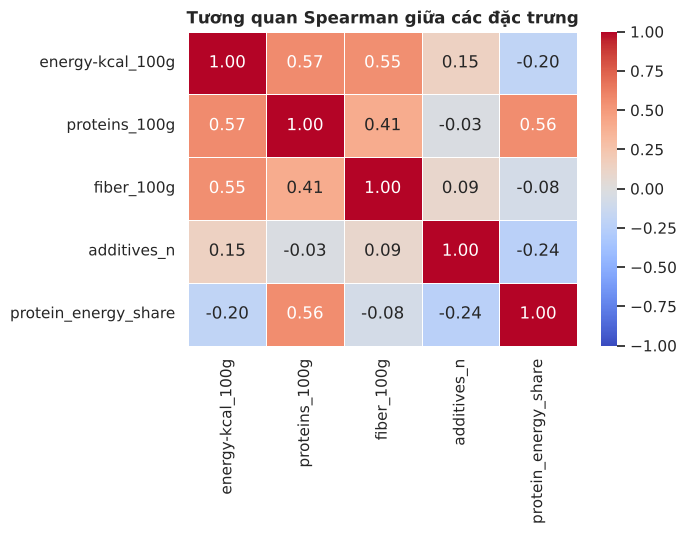

Các cặp |r| >= 0.85:
Series([], dtype: float64)


In [28]:
# 5.1 Tương quan Spearman giữa các đặc trưng (phát hiện đa cộng tuyến)
num = [c for c in FEATURES if c != "has_fiber"]
corr = train[num].corr(method="spearman")
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Tương quan Spearman giữa các đặc trưng", fontweight="bold")
plt.tight_layout()
plt.savefig("fe_feature_corr.png", dpi=120)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Các cặp |r| >= 0.85:")
print(pairs[pairs.abs() >= 0.85].round(2).sort_values(ascending=False))

                      mutual_info  duoc_chon
saturated-fat_100g          0.613      False
fat_100g                    0.603      False
energy-kcal_100g            0.526       True
sugars_100g                 0.252      False
protein_energy_share        0.233       True
proteins_100g               0.192       True
salt_100g                   0.147      False
fiber_100g                  0.059       True
additives_n                 0.008       True
has_fiber                   0.000       True


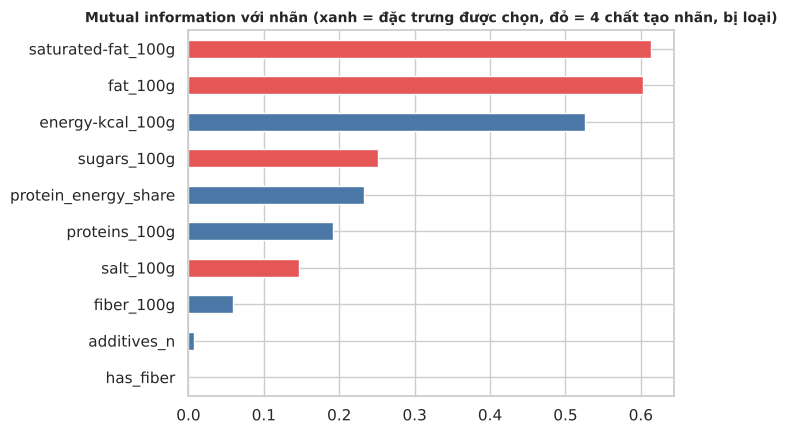

In [29]:
# 5.2 Mutual information với nhãn (đo mức thông tin mỗi biến cung cấp, kể cả quan hệ phi tuyến)
# Tính cho đặc trưng được chọn và cho 4 chất tạo nhãn (chỉ để cho thấy vì sao phải loại chúng)
cols = FEATURES + LABEL_NUTRIENTS
X = train[cols].copy()
X = X.fillna(X.median())
mi = pd.Series(mutual_info_classif(X, train["health_label"], random_state=SEED), index=cols).sort_values(ascending=False)
mi_tab = pd.DataFrame({"mutual_info": mi.round(3), "duoc_chon": [f in FEATURES for f in mi.index]})
print(mi_tab)
mi.sort_values().plot(kind="barh", figsize=(7, 4.5), color=["#4c78a8" if f in FEATURES else "#e45756" for f in mi.sort_values().index])
plt.title("Mutual information với nhãn (xanh = đặc trưng được chọn, đỏ = 4 chất tạo nhãn, bị loại)", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig("fe_mutual_info.png", dpi=120)
plt.show()

In [30]:
# 5.3 Kiểm tra giá trị thiếu của các đặc trưng
print((train[FEATURES].isna().mean() * 100).round(1))

energy-kcal_100g         0.0
proteins_100g            0.0
fiber_100g              30.6
additives_n              5.2
protein_energy_share     0.0
has_fiber                0.0
dtype: float64


**Nhận xét và quyết định chọn đặc trưng:**
- Béo bão hòa (0,61) và béo (0,60) có mutual information cao nhất, cao hơn cả năng lượng (0,53); đường (0,25) và muối (0,15) thấp hơn năng lượng. Dù vậy nhãn được tính trực tiếp từ cả 4 chất, nên đều phải **loại** khỏi bộ đặc trưng để mô hình không học lại công thức tạo nhãn.
- Bộ đặc trưng gồm: năng lượng, đạm, chất xơ, số phụ gia, % năng lượng từ đạm, cờ `has_fiber` và danh mục sản phẩm (one-hot trong pipeline ở Phần 3). Các biến số không có cặp nào tương quan quá cao (không có cặp |r| ≥ 0,85) nên giữ nguyên.
- Năng lượng là biến mang nhiều thông tin nhất vì phản ánh béo và đường gián tiếp, nhưng nó không phải là công thức tạo nhãn nên không gây rò rỉ trực tiếp.
- `additives_n` và `has_fiber` có mutual information gần 0, tức là đứng một mình gần như không phân biệt được nhãn. Vẫn giữ lại vì chi phí thấp, phụ gia liên quan tới NOVA (đã thấy ở EDA) và có thể bổ sung thông tin khi kết hợp với biến khác; Phần 4 sẽ kiểm tra lại bằng permutation importance.
- Chất xơ thiếu ~31% và phụ gia ~5%: **không điền ở đây**; sẽ điền trung vị bên trong pipeline và chỉ học trên tập train để tránh rò rỉ từ test.

## 7. Lưu bộ dữ liệu đặc trưng
Lưu riêng tập train và tập test để Phần 3 đọc thẳng, không phải chia lại. `feature_dataset.csv` là bản đầy đủ (có cột `split`), dùng cho K-Means và phần tổng hợp ở Phần 5.

In [31]:
# Giữ lại 4 chất tạo nhãn trong file dữ liệu (dùng cho K-Means ở Phần 3), nhưng KHÔNG dùng làm đặc trưng
keep = (["code", "product_name", "brand_main", "main_category", "country_single", "health_label", "fsa_points", "split"]
        + FEATURES + LABEL_NUTRIENTS + ["nutriscore_grade", "nova_group"])
keep = list(dict.fromkeys(keep))
df[keep].to_csv("feature_dataset.csv", index=False, encoding="utf-8-sig")
out = df[keep]
out[out["split"] == "train"].to_csv("train.csv", index=False, encoding="utf-8-sig")
out[out["split"] == "test"].to_csv("test.csv", index=False, encoding="utf-8-sig")
print("Đã lưu feature_dataset.csv:", out.shape, "| train.csv:", (out["split"] == "train").sum(), "| test.csv:", (out["split"] == "test").sum())
print("Đặc trưng:", FEATURES)

Đã lưu feature_dataset.csv: (7999, 20) | train.csv: 6399 | test.csv: 1600
Đặc trưng: ['energy-kcal_100g', 'proteins_100g', 'fiber_100g', 'additives_n', 'protein_energy_share', 'has_fiber']


## 8. Tóm tắt
- Nhãn 3 mức dựa trên ngưỡng FSA: Healthy 42,9%, Moderate 26,4%, Less Healthy 30,7%, tương đối cân bằng nên không cần lấy mẫu lại.
- Nhãn độc lập với Nutri-Score (chỉ khớp khoảng 65%) nên có thể dùng Nutri-Score để kiểm chứng chéo.
- Chia train/test 80/20 (6.399 / 1.600 sản phẩm), phân tầng theo nhãn và danh mục; mọi bước kiểm tra đặc trưng chỉ dùng tập train.
- Một bộ đặc trưng duy nhất (6 biến số + danh mục), đã loại 4 chất tạo nhãn để tránh rò rỉ dữ liệu.
- `train.csv` và `test.csv` được dùng cho Phần 3 (huấn luyện) và Phần 4 (đánh giá); danh sách `FEATURES` được khai báo lại ở đầu Phần 3 và Phần 4 kèm lệnh kiểm tra không chứa 4 chất tạo nhãn.

# Phần 3 – Huấn luyện mô hình

**Mục tiêu:** huấn luyện các mô hình dự đoán nhãn **Healthy / Moderate / Less Healthy** (RQ5) và chạy phân cụm K-Means (riêng, không giám sát).

**Quy trình**
1. Đọc `train.csv` và `test.csv` (đã chia 80/20 ở Phần 2) và khai báo bộ đặc trưng `FEATURES`.
2. Hai mô hình: **Logistic Regression** và **Random Forest**, mỗi mô hình nằm trong một pipeline (điền thiếu, chuẩn hóa, one-hot).
3. Cross-validation 5 lần **chỉ trên tập train** để so sánh mô hình; sau đó huấn luyện lại trên toàn bộ train và lưu mô hình.
4. Phân cụm K-Means (không giám sát).

Tập test **không được dùng ở phần này**; việc tính các chỉ số trên test nằm ở Phần 4.


## 1. Đọc dữ liệu và thiết lập

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, f1_score, adjusted_rand_score, silhouette_score
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEED = 42
LABELS = ["Healthy", "Moderate", "Less Healthy"]
LABEL_NUTRIENTS = ["fat_100g", "saturated-fat_100g", "sugars_100g", "salt_100g"]
# Phải trùng với FEATURES đã chọn ở Phần 2 (không chứa 4 chất tạo nhãn)
FEATURES = ["energy-kcal_100g", "proteins_100g", "fiber_100g", "additives_n", "protein_energy_share", "has_fiber"]

assert not set(LABEL_NUTRIENTS) & set(FEATURES), "Đặc trưng không được chứa 4 chất tạo nhãn"
assert not {"nutriscore_grade", "nutriscore_score", "nova_group", "fsa_points", "health_label"} & set(FEATURES)
train = pd.read_csv("train.csv", dtype={"code": str})
test = pd.read_csv("test.csv", dtype={"code": str})
y_train = train["health_label"]
print("train:", train.shape, " test:", test.shape)
print(y_train.value_counts().reindex(LABELS))

train: (6399, 20)  test: (1600, 20)
health_label
Healthy         2748
Moderate        1687
Less Healthy    1964
Name: count, dtype: int64


## 2. Pipeline, cross-validation và huấn luyện

In [33]:
def make_pipeline(features, model):
    """Điền trung vị + chuẩn hóa cho biến số, one-hot cho danh mục. Tất cả chỉ fit trên train."""
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["main_category"]),
    ])
    return Pipeline([("pre", pre), ("model", model)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced",
                                            random_state=SEED, n_jobs=-1),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
Xtr = train[FEATURES + ["main_category"]]

rows = []
for name, model in models.items():
    pipe = make_pipeline(FEATURES, model)
    cvr = cross_validate(pipe, Xtr, y_train, cv=cv,
                         scoring=["accuracy", "precision_macro", "recall_macro", "f1_macro"])
    rows.append({"mo_hinh": name,
                 "CV_accuracy": cvr["test_accuracy"].mean(), "CV_precision_macro": cvr["test_precision_macro"].mean(),
                 "CV_recall_macro": cvr["test_recall_macro"].mean(), "CV_f1_macro": cvr["test_f1_macro"].mean(),
                 "CV_f1_std": cvr["test_f1_macro"].std()})
    pipe.fit(Xtr, y_train)                                   # huấn luyện lại trên toàn bộ train
    joblib.dump(pipe, "model_" + name.lower().replace(" ", "_") + ".joblib")

cv_results = pd.DataFrame(rows)
print(cv_results.round(3).to_string(index=False))
cv_results.to_csv("cv_results.csv", index=False, encoding="utf-8-sig")
print("\nĐã lưu cv_results.csv và hai file mô hình .joblib")

            mo_hinh  CV_accuracy  CV_precision_macro  CV_recall_macro  CV_f1_macro  CV_f1_std
Logistic Regression        0.794               0.774            0.776        0.774      0.002
      Random Forest        0.836               0.825            0.831        0.827      0.006

Đã lưu cv_results.csv và hai file mô hình .joblib


**Nhận xét:**
- Trong cross-validation 5 lần trên tập train, **Random Forest** vượt Logistic Regression ở mọi chỉ số: accuracy 0,836 so với 0,794, F1 macro 0,827 so với 0,774. Độ lệch chuẩn F1 giữa 5 fold nhỏ (0,006 với Random Forest, 0,002 với Logistic Regression) nên kết quả ổn định.
- Random Forest tốt hơn vì quan hệ giữa năng lượng, đạm và nhãn là phi tuyến.
- Bộ đặc trưng đã loại 4 chất tạo nhãn nên các con số này không phải do mô hình học lại công thức tính nhãn. Năng lượng vẫn mang thông tin gián tiếp về béo và đường (xem Phần 5).
- Cả hai mô hình đã được huấn luyện lại trên toàn bộ train và lưu thành file `.joblib`; điểm trên tập test được tính ở Phần 4.

## 3. Phân cụm K-Means (kiểm chứng nhóm tự nhiên)

In [34]:
CL = ["energy-kcal_100g", "fat_100g", "saturated-fat_100g", "sugars_100g", "salt_100g", "proteins_100g"]
data = pd.read_csv("feature_dataset.csv", dtype={"code": str})   # K-Means không giám sát, mô tả toàn bộ 7.999 sản phẩm
Xc = StandardScaler().fit_transform(np.log1p(data[CL]))

# Chọn k bằng silhouette
ks = range(2, 7)
sil = {k: silhouette_score(Xc, KMeans(k, n_init=10, random_state=SEED).fit_predict(Xc), sample_size=4000, random_state=SEED) for k in ks}
print("Silhouette theo k:", {k: round(v, 3) for k, v in sil.items()})

km = KMeans(3, n_init=10, random_state=SEED).fit(Xc)
data["cluster"] = km.labels_
print("\nARI giữa cụm K-Means (k=3) và nhãn FSA:", round(adjusted_rand_score(data["health_label"], data["cluster"]), 3))
print("\nHồ sơ trung bình mỗi cụm:")
prof = data.groupby("cluster")[CL].mean().round(2)
prof["n"] = data["cluster"].value_counts().sort_index()
print(prof)
print("\nCụm x nhãn FSA (% theo cụm):")
print((pd.crosstab(data["cluster"], data["health_label"], normalize="index")[LABELS] * 100).round(1))
print("\nCụm x danh mục (% theo cụm):")
print((pd.crosstab(data["cluster"], data["main_category"], normalize="index") * 100).round(1))

Silhouette theo k: {2: 0.354, 3: 0.343, 4: 0.308, 5: 0.321, 6: 0.325}

ARI giữa cụm K-Means (k=3) và nhãn FSA: 0.431

Hồ sơ trung bình mỗi cụm:
         energy-kcal_100g  fat_100g  saturated-fat_100g  sugars_100g  salt_100g  proteins_100g     n
cluster                                                                                             
0                   68.31      1.50                0.61         5.98       0.25           2.93  3407
1                  297.50     16.75                7.35         2.66       1.42          11.37  2718
2                  444.81     25.60               13.08        27.32       0.35           6.65  1874

Cụm x nhãn FSA (% theo cụm):
health_label  Healthy  Moderate  Less Healthy
cluster                                      
0                87.2      12.7           0.1
1                16.0      47.2          36.8
2                 1.5      21.2          77.3

Cụm x danh mục (% theo cụm):
main_category  beverages  dairies  meals  snacks
cluster     

**Nhận xét:**
- Silhouette cao nhất ở k = 2 (0,354) và k = 3 (0,343) gần bằng nhau; chọn k = 3 để so sánh với 3 nhãn.
- 3 cụm có ý nghĩa rõ: **cụm 0** (3.407 sản phẩm) năng lượng thấp (68 kcal), phần lớn là đồ uống, sữa, meals, 87,2% Healthy; **cụm 1** (2.718) béo vừa, muối cao nhất (1,42 g) và đạm cao (11,4 g), chủ yếu meals và dairies, nhãn hỗn hợp (47,2% Moderate, 36,8% Less Healthy, 16,0% Healthy); **cụm 2** (1.874) năng lượng, béo và đường cao nhất (445 kcal, 27 g đường), 75% là snacks, 77,3% Less Healthy.
- ARI với nhãn FSA là 0,431: phân cụm không giám sát tái tạo khá tốt nhóm tự nhiên nhưng không trùng hoàn toàn với nhãn (cụm 1 trộn lẫn cả ba mức). Kết quả ủng hộ việc ba mức nhãn có cơ sở trong dữ liệu.
- Lưu ý: K-Means dùng cả 4 chất tạo nhãn (không giám sát, không dùng để dự đoán), nên ARI với nhãn FSA một phần là hiển nhiên; chỉ nên đọc như bằng chứng tham khảo rằng ba nhóm tự nhiên khớp tương đối với ba mức nhãn, không phải kiểm chứng độc lập.
- Phần so sánh đầy đủ giữa K-Means và nhãn FSA (bảng crosstab, heatmap, ARI, NMI) nằm ở mục 7 của Phần 4.

# Phần 4 – Đánh giá hiệu năng mô hình

**Mục tiêu:** đánh giá hai mô hình đã huấn luyện ở Phần 3 trên **tập test** (1.600 sản phẩm) và tìm yếu tố quan trọng nhất (RQ4).

**Nội dung**
1. Đọc dữ liệu test và nạp mô hình đã lưu.
2. Các chỉ số: Accuracy, Precision, Recall, F1-score (macro và theo từng lớp).
3. Ma trận nhầm lẫn (Confusion Matrix).
4. ROC-AUC.
5. Độ quan trọng của đặc trưng (Feature Importance).
6. Phần mở rộng: đối chiếu với Nutri-Score và hiệu năng theo danh mục.
7. So sánh K-Means với nhãn tự xây dựng (Crosstab, Heatmap, ARI, NMI).
8. So sánh Logistic Regression và Random Forest (Accuracy, Macro F1, Weighted F1, F1 theo từng nhãn).

Mô hình tốt nhất được chọn theo **F1 macro cross-validation trên tập train** (Phần 3), không chọn theo điểm test để tập test không tham gia vào việc lựa chọn.

| | |
|---|---|
| **Đầu vào** | `train.csv`, `test.csv`, `feature_dataset.csv`, `cv_results.csv`, hai file mô hình `.joblib` (do Phần 3 tạo ra) |
| **Đầu ra** | `test_metrics.csv`, `feature_importance.csv`, `performance_by_category.csv`, `best_model.csv`, `kmeans_vs_label_crosstab.csv`, `kmeans_vs_label_metrics.csv`, `model_comparison.csv`, `per_class_metrics.csv`, `ml_*.png` |

## 1. Đọc dữ liệu và nạp mô hình

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score, auc)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEED = 42
LABELS = ["Healthy", "Moderate", "Less Healthy"]
LABEL_NUTRIENTS = ["fat_100g", "saturated-fat_100g", "sugars_100g", "salt_100g"]
# Phải trùng với FEATURES đã chọn ở Phần 2 (không chứa 4 chất tạo nhãn)
FEATURES = ["energy-kcal_100g", "proteins_100g", "fiber_100g", "additives_n", "protein_energy_share", "has_fiber"]
assert not set(LABEL_NUTRIENTS) & set(FEATURES), "Đặc trưng không được chứa 4 chất tạo nhãn"

test = pd.read_csv("test.csv", dtype={"code": str})
y_test = test["health_label"]
Xte = test[FEATURES + ["main_category"]]
print("test:", test.shape)

fitted = {"Logistic Regression": joblib.load("model_logistic_regression.joblib"),
          "Random Forest": joblib.load("model_random_forest.joblib")}
cv_res = pd.read_csv("cv_results.csv")
best_name = cv_res.sort_values("CV_f1_macro", ascending=False).iloc[0]["mo_hinh"]
print("Mô hình tốt nhất theo F1 macro cross-validation (train):", best_name)

test: (1600, 20)
Mô hình tốt nhất theo F1 macro cross-validation (train): Random Forest


## 2. Accuracy, Precision, Recall, F1-score

In [36]:
# Chỉ số tổng hợp trên tập test (Precision, Recall, F1 là trung bình macro: mỗi lớp có trọng số như nhau)
rows, proba, preds = [], {}, {}
for name, pipe in fitted.items():
    preds[name] = pipe.predict(Xte)
    proba[name] = pipe.predict_proba(Xte)
    rows.append({"mo_hinh": name,
                 "Accuracy": accuracy_score(y_test, preds[name]),
                 "Precision_macro": precision_score(y_test, preds[name], average="macro"),
                 "Recall_macro": recall_score(y_test, preds[name], average="macro"),
                 "F1_macro": f1_score(y_test, preds[name], average="macro"),
                 "ROC_AUC_macro_ovr": roc_auc_score(y_test, proba[name], multi_class="ovr", average="macro",
                                                   labels=list(pipe.classes_))})
test_metrics = pd.DataFrame(rows)
print(test_metrics.round(3).to_string(index=False))
test_metrics.to_csv("test_metrics.csv", index=False, encoding="utf-8-sig")

best = fitted[best_name]
pred = preds[best_name]
print("\nSo sánh F1 macro: cross-validation (train) và test")
print(cv_res[["mo_hinh", "CV_f1_macro"]].merge(test_metrics[["mo_hinh", "F1_macro"]], on="mo_hinh").round(3).to_string(index=False))

            mo_hinh  Accuracy  Precision_macro  Recall_macro  F1_macro  ROC_AUC_macro_ovr
Logistic Regression     0.784            0.761         0.764     0.761              0.908
      Random Forest     0.836            0.824         0.831     0.827              0.950

So sánh F1 macro: cross-validation (train) và test
            mo_hinh  CV_f1_macro  F1_macro
Logistic Regression        0.774     0.761
      Random Forest        0.827     0.827


**Nhận xét:**
- **Random Forest** vượt Logistic Regression ở mọi chỉ số trên tập test: accuracy 0,836 so với 0,784; precision macro 0,824 so với 0,761; recall macro 0,831 so với 0,764; F1 macro 0,827 so với 0,761; ROC-AUC macro 0,950 so với 0,908.
- Điểm test sát điểm cross-validation (F1 macro của Random Forest: 0,827 và 0,827; của Logistic Regression: 0,774 và 0,761), nên không có dấu hiệu overfit rõ rệt.
- Random Forest cũng là mô hình được chọn theo cross-validation, nên việc chọn mô hình không dựa vào tập test.

In [37]:
# Báo cáo theo từng lớp (Precision, Recall, F1) cho hai mô hình
for name in fitted:
    print("=" * 60); print(name); print("=" * 60)
    print(classification_report(y_test, preds[name], labels=LABELS, digits=3))

Logistic Regression
              precision    recall  f1-score   support

     Healthy      0.850     0.857     0.854       687
    Moderate      0.617     0.541     0.577       423
Less Healthy      0.815     0.892     0.852       490

    accuracy                          0.784      1600
   macro avg      0.761     0.764     0.761      1600
weighted avg      0.778     0.784     0.780      1600

Random Forest
              precision    recall  f1-score   support

     Healthy      0.921     0.844     0.881       687
    Moderate      0.691     0.745     0.717       423
Less Healthy      0.862     0.904     0.882       490

    accuracy                          0.836      1600
   macro avg      0.824     0.831     0.827      1600
weighted avg      0.842     0.836     0.838      1600



**Nhận xét theo lớp (Random Forest):** Healthy (precision 0,921, recall 0,844) và Less Healthy (0,862 / 0,904) được nhận ra tốt; **Moderate yếu nhất** (0,691 / 0,745, F1 0,717) vì là nhóm trung gian của quy tắc gán nhãn (không đủ "xanh" để là Healthy, chưa đủ "đỏ" để là Less Healthy) nên ranh giới sát hai lớp bên cạnh. Logistic Regression yếu hơn rõ ở Moderate: recall chỉ 0,541 (F1 0,577), tức gần một nửa số sản phẩm Moderate bị gán sang lớp khác.

## 3. Ma trận nhầm lẫn (Confusion Matrix)

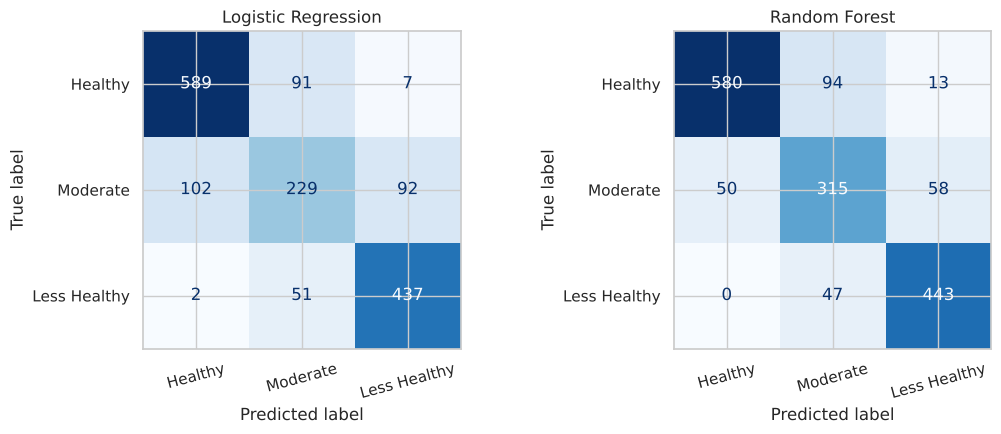

In [38]:
# Ma trận nhầm lẫn: so sánh hai mô hình
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ["Logistic Regression", "Random Forest"]):
    p = fitted[name].predict(Xte)
    ConfusionMatrixDisplay.from_predictions(y_test, p, labels=LABELS, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("ml_confusion_matrix.png", dpi=120)
plt.show()

**Nhận xét:** với Random Forest, hầu hết lỗi xảy ra giữa các lớp **kề nhau**: 94 sản phẩm Healthy bị đoán Moderate, 50 Moderate bị đoán Healthy, 47 Less Healthy bị đoán Moderate và 58 Moderate bị đoán Less Healthy. Rất hiếm khi nhầm hai đầu mút (chỉ 13 Healthy bị đoán Less Healthy và không có trường hợp ngược lại), nên mức độ sai lệch nhìn chung nhẹ.

## 4. ROC-AUC

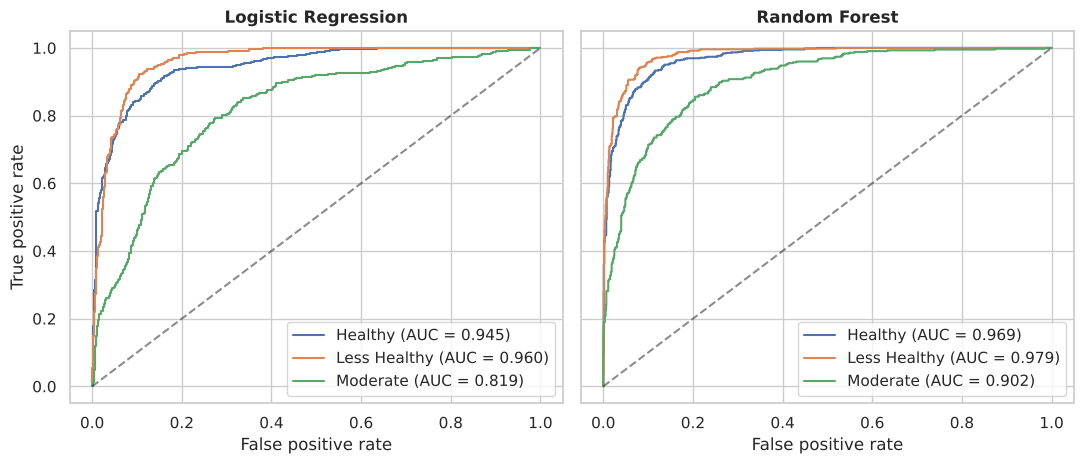

              Logistic Regression  Random Forest
Healthy                     0.945          0.969
Moderate                    0.819          0.902
Less Healthy                0.960          0.979


In [39]:
# ROC one-vs-rest cho cả hai mô hình
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
auc_tab = {}
for ax, (name, pipe) in zip(axes, fitted.items()):
    classes = list(pipe.classes_)
    Y = label_binarize(y_test, classes=classes)
    auc_tab[name] = {}
    for i, cl in enumerate(classes):
        fpr, tpr, _ = roc_curve(Y[:, i], proba[name][:, i])
        auc_tab[name][cl] = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{cl} (AUC = {auc_tab[name][cl]:.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("False positive rate")
    ax.legend(loc="lower right")
axes[0].set_ylabel("True positive rate")
plt.tight_layout()
plt.savefig("ml_roc.png", dpi=120)
plt.show()

print(pd.DataFrame(auc_tab).reindex(LABELS).round(3))
auc_rows = auc_tab[best_name]

**Nhận xét:** AUC one-vs-rest của Random Forest cao ở cả ba lớp: Less Healthy 0,979, Healthy 0,969 và Moderate 0,902 (macro 0,950). Logistic Regression thấp hơn: 0,960, 0,945 và 0,819 (macro 0,908). Moderate thấp nhất ở cả hai mô hình, đúng với kết quả phân loại ở trên.

## 5. Độ quan trọng của đặc trưng (Feature Importance, RQ4)

           dac_trung  giam_F1    std
    energy-kcal_100g   0.4538 0.0108
       main_category   0.1161 0.0066
          fiber_100g   0.0353 0.0034
protein_energy_share   0.0296 0.0050
       proteins_100g   0.0239 0.0041
         additives_n   0.0205 0.0039
           has_fiber   0.0025 0.0015


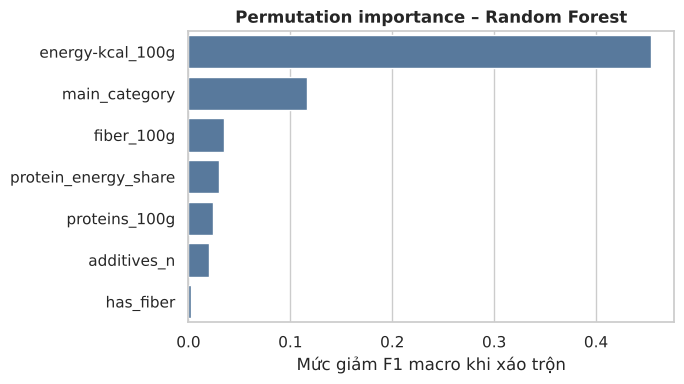

In [40]:
# Permutation importance trên tập test: đo F1 giảm bao nhiêu khi xáo trộn một đặc trưng
feat_names = FEATURES + ["main_category"]
pi = permutation_importance(best, Xte, y_test, n_repeats=20, random_state=SEED, scoring="f1_macro", n_jobs=-1)
imp = pd.DataFrame({"dac_trung": feat_names, "giam_F1": pi.importances_mean, "std": pi.importances_std}).sort_values("giam_F1", ascending=False)
print(imp.round(4).to_string(index=False))

plt.figure(figsize=(7, 4))
sns.barplot(data=imp, y="dac_trung", x="giam_F1", color="#4c78a8")
plt.title(f"Permutation importance – {best_name}", fontweight="bold")
plt.xlabel("Mức giảm F1 macro khi xáo trộn")
plt.ylabel("")
plt.tight_layout()
plt.savefig("ml_feature_importance.png", dpi=120)
plt.show()

**Nhận xét (RQ4):**
- **Năng lượng** áp đảo: xáo trộn nó làm F1 giảm 0,45, gấp gần 4 lần biến đứng thứ hai.
- Tiếp theo là **danh mục sản phẩm** (giảm 0,116), rồi chất xơ (0,035), % năng lượng từ đạm (0,030), đạm (0,024) và phụ gia (0,021); `has_fiber` gần như không đóng góp (0,003).
- Lưu ý: năng lượng được tính từ béo, đường, đạm nên nó mang theo thông tin gián tiếp về béo và đường. Vì vậy kết luận hợp lý là: nhãn chất lượng chủ yếu do **mật độ năng lượng** quyết định, chứ không nên hiểu là béo và đường không quan trọng.

In [41]:
# Hệ số Logistic Regression (cho biết chiều ảnh hưởng, đã chuẩn hóa nên so sánh được)
lr = fitted["Logistic Regression"]
names = FEATURES + list(lr.named_steps["pre"].named_transformers_["cat"].get_feature_names_out(["main_category"]))
coef = pd.DataFrame(lr.named_steps["model"].coef_, index=lr.named_steps["model"].classes_, columns=names).T
print(coef.round(2).loc[FEATURES])

                      Healthy  Less Healthy  Moderate
energy-kcal_100g        -3.24          3.36     -0.12
proteins_100g           -0.63          0.60      0.03
fiber_100g               0.32         -0.28     -0.04
additives_n             -0.13          0.11      0.02
protein_energy_share     0.62         -0.74      0.12
has_fiber                0.14         -0.17      0.03


**Nhận xét:** hệ số Logistic Regression (đã chuẩn hóa) khớp với trực giác: năng lượng cao làm tăng khả năng Less Healthy (+3,36) và giảm khả năng Healthy (−3,24). Đạm tuyệt đối cao đi nhẹ về phía Less Healthy (+0,60) trong khi % năng lượng từ đạm cao đi về phía Healthy (+0,62): sản phẩm nhiều đạm tuyệt đối thường là phô mai, thịt (nhiều béo, năng lượng cao), còn tỷ lệ đạm trên năng lượng cao thường là sản phẩm nhẹ, ít béo. Phụ gia có hệ số rất nhỏ.

## 6. Phần mở rộng

### 6.1 Đối chiếu với Nutri-Score (kiểm chứng chéo)

In [42]:
# Chỉ xét sản phẩm test có Nutri-Score
t = test.copy()
t["pred"] = pred
t["nutri_3"] = t["nutriscore_grade"].map({"A": "Healthy", "B": "Healthy", "C": "Moderate", "D": "Less Healthy", "E": "Less Healthy"})
t = t.dropna(subset=["nutri_3"])
print("Số sản phẩm test có Nutri-Score:", len(t))
print("Nhãn FSA (thật) khớp Nutri-Score gộp :", round((t["health_label"] == t["nutri_3"]).mean() * 100, 1), "%")
print("Mô hình dự đoán khớp Nutri-Score gộp:", round((t["pred"] == t["nutri_3"]).mean() * 100, 1), "%")
print("Mô hình dự đoán khớp nhãn FSA        :", round((t["pred"] == t["health_label"]).mean() * 100, 1), "%")
print("\nHàng: Nutri-Score gộp, cột: dự đoán của mô hình")
print(pd.crosstab(t["nutri_3"], t["pred"]).reindex(index=LABELS, columns=LABELS))

Số sản phẩm test có Nutri-Score: 1515
Nhãn FSA (thật) khớp Nutri-Score gộp : 67.3 %
Mô hình dự đoán khớp Nutri-Score gộp: 65.4 %
Mô hình dự đoán khớp nhãn FSA        : 84.0 %

Hàng: Nutri-Score gộp, cột: dự đoán của mô hình
pred          Healthy  Moderate  Less Healthy
nutri_3                                      
Healthy           329        52             8
Moderate          189       228            53
Less Healthy       73       149           434


**Nhận xét:**
- Mô hình dự đoán khớp nhãn FSA ở mức 84,0% trong khi khớp Nutri-Score gộp 65,4%, gần bằng mức khớp giữa chính nhãn FSA và Nutri-Score (67,3%). Điều này cho thấy mô hình học đúng **nhãn của nhóm**, và sự lệch với Nutri-Score chủ yếu do hai hệ thống chấm khác nhau (Nutri-Score tính thêm đạm, chất xơ, rau quả), không phải do mô hình sai.
- Phần lớn sai lệch là sản phẩm Nutri-Score Moderate (C) bị mô hình đoán Healthy (189 sản phẩm) hoặc Nutri-Score Less Healthy (D, E) bị đoán Moderate (149).

### 6.2 Hiệu năng theo danh mục và lưu kết quả

In [43]:
t2 = test.copy()
t2["pred"] = pred
by_cat = pd.DataFrame({
    cat: {"n": len(g), "accuracy": accuracy_score(g["health_label"], g["pred"]),
          "f1_macro": f1_score(g["health_label"], g["pred"], average="macro")}
    for cat, g in t2.groupby("main_category")}).T
by_cat.index.name = "main_category"
print(by_cat.round(3))

imp.to_csv("feature_importance.csv", index=False, encoding="utf-8-sig")
by_cat.to_csv("performance_by_category.csv", encoding="utf-8-sig")
pd.DataFrame({"best_model": best_name, "class": list(auc_rows), "auc": [float(v) for v in auc_rows.values()]}).to_csv(
    "best_model.csv", index=False, encoding="utf-8-sig")
print("Đã lưu feature_importance.csv, performance_by_category.csv, best_model.csv")

                   n  accuracy  f1_macro
main_category                           
beverages      283.0     0.894     0.797
dairies        443.0     0.916     0.891
meals          433.0     0.755     0.609
snacks         441.0     0.798     0.699
Đã lưu feature_importance.csv, performance_by_category.csv, best_model.csv


**Nhận xét:** mô hình hoạt động tốt nhất ở dairies (accuracy 0,916, F1 0,891). Beverages có accuracy 0,894 nhưng F1 macro chỉ 0,797 vì lớp Less Healthy rất ít mẫu (14 sản phẩm trong tập test). Kém hơn ở snacks (F1 0,699) và nhất là meals (0,609): meals chỉ có 16 sản phẩm Less Healthy trong tập test và mô hình chỉ nhận ra khoảng 19% trong số đó, kéo F1 macro xuống dù accuracy vẫn đạt 0,755. Khi triển khai cần báo cáo theo danh mục chứ không chỉ một con số chung.

## 7. So sánh K-Means với nhãn tự xây dựng (Healthy / Moderate / Less Healthy)

**Mục đích:** K-Means là phương pháp **không giám sát**, không hề biết nhãn của nhóm. Nếu các cụm K-Means (chỉ dựa vào thành phần dinh dưỡng) trùng khá nhiều với nhãn FSA thì ba mức nhãn có cơ sở trong chính dữ liệu, chứ không phải do nhóm áp đặt. Ngược lại, chỗ hai cách phân nhóm khác nhau cho thấy nhãn FSA (dựa trên điểm số) cắt dữ liệu theo cách khác với hình dạng tự nhiên của dữ liệu.

Cấu hình K-Means giữ **y hệt Phần 3** (6 chất dinh dưỡng, `log1p` + chuẩn hóa, k = 3, `random_state = 42`) trên toàn bộ 7.999 sản phẩm. Để dễ đọc, các cụm được đánh số lại theo năng lượng trung bình tăng dần (cụm 0 thấp nhất, cụm 2 cao nhất); việc đánh số lại không làm đổi ARI/NMI.

### 7.1 Bảng Crosstab: số lượng và tỷ lệ nhãn trong từng cụm

In [44]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

CL = ["energy-kcal_100g", "fat_100g", "saturated-fat_100g", "sugars_100g", "salt_100g", "proteins_100g"]
data = pd.read_csv("feature_dataset.csv", dtype={"code": str})
Xc = StandardScaler().fit_transform(np.log1p(data[CL]))
km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xc)

# Đánh số lại cụm theo năng lượng trung bình tăng dần (chỉ đổi tên cụm, không đổi kết quả phân cụm)
order = data.groupby(km.labels_)["energy-kcal_100g"].mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
data["cluster"] = pd.Series(km.labels_).map(remap).values

# Crosstab số lượng và tỷ lệ (% theo từng cụm)
ct_n = pd.crosstab(data["cluster"], data["health_label"])[LABELS]
ct_n["Tổng"] = ct_n.sum(axis=1)
ct_p = (pd.crosstab(data["cluster"], data["health_label"], normalize="index")[LABELS] * 100).round(1)

ct = pd.concat({"Số lượng": ct_n, "Tỷ lệ % trong cụm": ct_p}, axis=1)
ct.index.name = "Cụm"
print(ct.to_string())

# Phần trăm theo nhãn (mỗi nhãn nằm ở những cụm nào) để nhìn từ phía nhãn
ct_col = (pd.crosstab(data["cluster"], data["health_label"], normalize="columns")[LABELS] * 100).round(1)
print("\nTỷ lệ % theo NHÃN (mỗi cột cộng lại = 100%):")
print(ct_col.to_string())

# Hồ sơ dinh dưỡng trung bình mỗi cụm để gọi tên cụm
prof = data.groupby("cluster")[CL].mean().round(2)
prof["n"] = data["cluster"].value_counts().sort_index()
print("\nHồ sơ trung bình mỗi cụm:")
print(prof.to_string())

ct.to_csv("kmeans_vs_label_crosstab.csv", encoding="utf-8-sig")

             Số lượng                             Tỷ lệ % trong cụm                      
health_label  Healthy Moderate Less Healthy  Tổng           Healthy Moderate Less Healthy
Cụm                                                                                      
0                2971      431            5  3407              87.2     12.7          0.1
1                 436     1282         1000  2718              16.0     47.2         36.8
2                  28      397         1449  1874               1.5     21.2         77.3

Tỷ lệ % theo NHÃN (mỗi cột cộng lại = 100%):
health_label  Healthy  Moderate  Less Healthy
cluster                                      
0                86.5      20.4           0.2
1                12.7      60.8          40.7
2                 0.8      18.8          59.0

Hồ sơ trung bình mỗi cụm:
         energy-kcal_100g  fat_100g  saturated-fat_100g  sugars_100g  salt_100g  proteins_100g     n
cluster                                                 

**Nhận xét:**
- **Cụm 0** (3.407 sản phẩm, năng lượng trung bình 68 kcal) gần như là nhóm Healthy: 2.971 sản phẩm, **87,2%**; chỉ có 5 sản phẩm Less Healthy (0,1%).
- **Cụm 2** (1.874 sản phẩm, 445 kcal, 27 g đường, 13 g chất béo bão hòa) nghiêng hẳn về Less Healthy: 1.449 sản phẩm, **77,3%**; chỉ 1,5% là Healthy.
- **Cụm 1** (2.718 sản phẩm, béo vừa, muối cao nhất 1,42 g, đạm cao 11,4 g) là cụm **lẫn nhất**: Moderate 47,2%, Less Healthy 36,8%, Healthy 16,0%.
- Nhìn từ phía nhãn: 86,5% sản phẩm Healthy nằm ở cụm 0, nhưng sản phẩm **Moderate bị chia ba**: 20,4% ở cụm 0, 60,8% ở cụm 1, 18,8% ở cụm 2.

### 7.2 Heatmap phân bố nhãn trong từng cụm

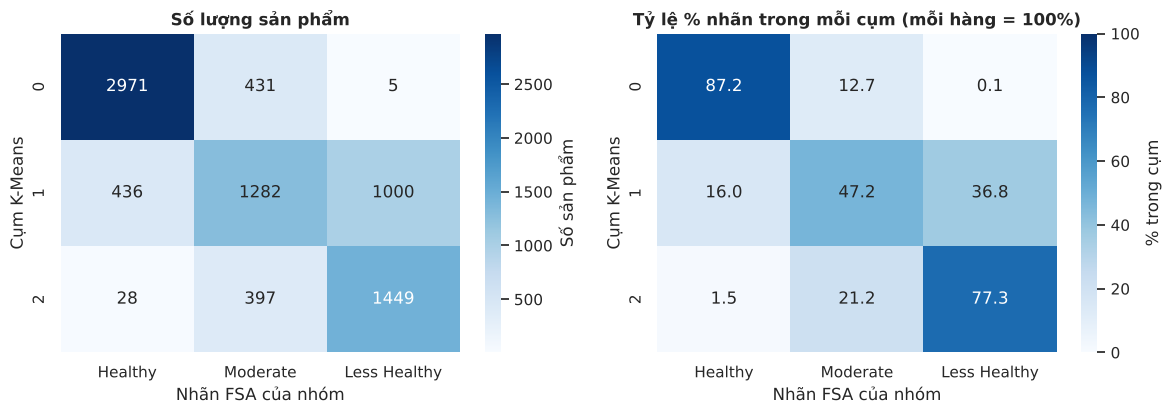

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
sns.heatmap(ct_n[LABELS], annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar_kws={"label": "Số sản phẩm"})
axes[0].set_title("Số lượng sản phẩm", fontweight="bold")
sns.heatmap(ct_p, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, ax=axes[1], cbar_kws={"label": "% trong cụm"})
axes[1].set_title("Tỷ lệ % nhãn trong mỗi cụm (mỗi hàng = 100%)", fontweight="bold")
for ax in axes:
    ax.set_xlabel("Nhãn FSA của nhóm")
    ax.set_ylabel("Cụm K-Means")
plt.tight_layout()
plt.savefig("ml_kmeans_label_heatmap.png", dpi=120)
plt.show()

**Nhận xét:** heatmap có hai ô đậm ở hai đầu (cụm 0 × Healthy và cụm 2 × Less Healthy), tức K-Means tách tốt hai nhóm cực. Hàng giữa (cụm 1) màu loang đều trên cả ba nhãn, nên cụm này không tương ứng với riêng mức nhãn nào. Nhãn Moderate không có cụm "của riêng mình": ô đậm nhất của nó (cụm 1) cũng chỉ chiếm 47,2% cụm.

### 7.3 ARI và NMI giữa K-Means và nhãn của nhóm

In [46]:
ari = adjusted_rand_score(data["health_label"], data["cluster"])
nmi = normalized_mutual_info_score(data["health_label"], data["cluster"])
# Độ thuần (purity): nếu gán mỗi cụm bằng nhãn chiếm đa số thì đúng bao nhiêu % sản phẩm
purity = ct_n[LABELS].max(axis=1).sum() / len(data)
maj = ct_n[LABELS].idxmax(axis=1).to_dict()

print(f"ARI (Adjusted Rand Index)          : {ari:.3f}")
print(f"NMI (Normalized Mutual Information): {nmi:.3f}")
print(f"Purity (gán cụm theo nhãn đa số)   : {purity:.3f}")
print("Nhãn chiếm đa số của từng cụm      :", maj)

# Đối chiếu: các cụm K-Means có giống danh mục sản phẩm không? (mốc tham chiếu)
ari_cat = adjusted_rand_score(data["main_category"], data["cluster"])
nmi_cat = normalized_mutual_info_score(data["main_category"], data["cluster"])
print(f"\nTham chiếu: K-Means vs main_category -> ARI = {ari_cat:.3f}, NMI = {nmi_cat:.3f}")

pd.DataFrame({"chi_so": ["ARI", "NMI", "Purity", "ARI_vs_main_category", "NMI_vs_main_category"],
              "gia_tri": [ari, nmi, purity, ari_cat, nmi_cat]}).to_csv("kmeans_vs_label_metrics.csv", index=False, encoding="utf-8-sig")

ARI (Adjusted Rand Index)          : 0.431
NMI (Normalized Mutual Information): 0.398
Purity (gán cụm theo nhãn đa số)   : 0.713
Nhãn chiếm đa số của từng cụm      : {0: 'Healthy', 1: 'Moderate', 2: 'Less Healthy'}

Tham chiếu: K-Means vs main_category -> ARI = 0.191, NMI = 0.262


**Nhận xét:**
- **ARI = 0,431** và **NMI = 0,398**: hai cách phân nhóm giống nhau ở **mức trung bình, rõ hơn ngẫu nhiên nhiều** (ARI = 0 là ngẫu nhiên, 1 là trùng khớp hoàn toàn) nhưng chưa trùng khớp. Nếu gán mỗi cụm bằng nhãn chiếm đa số thì đúng 71,3% sản phẩm (purity).
- Để có mốc so sánh: K-Means với **danh mục sản phẩm** chỉ đạt ARI = 0,191 và NMI = 0,262, thấp hơn nhiều, nên các cụm phản ánh mức độ dinh dưỡng nhiều hơn là chuyện sản phẩm thuộc loại nào.
- **Lưu ý khi diễn giải:** K-Means dùng cả 4 chất tạo nhãn (chất béo, chất béo bão hòa, đường, muối) mà nhãn FSA cũng được tính từ chính các chất này. Vì vậy một phần sự giống nhau là hiển nhiên, và kết quả này không phải kiểm chứng độc lập hoàn toàn.

### 7.4 Nhận xét tổng hợp: giống và khác nhau giữa K-Means và nhãn FSA

**Giống nhau**
- Hai cách phân nhóm cùng sắp xếp sản phẩm theo một **trục chung từ ít đến nhiều năng lượng, béo, đường**: cụm 0 ↔ Healthy, cụm 2 ↔ Less Healthy. Hai đầu mút khớp rõ (87,2% và 77,3%), và gần như không có sản phẩm nhảy từ Healthy sang Less Healthy hay ngược lại (cụm 0 chỉ có 5 Less Healthy; cụm 2 chỉ 28 Healthy).
- ARI 0,431 và NMI 0,398 cho thấy ba mức nhãn của nhóm **có cơ sở trong cấu trúc dữ liệu**, không phải cách chia tùy ý.

**Khác nhau**
- **Moderate là nhãn khớp kém nhất.** K-Means không tạo ra cụm nào tương ứng với Moderate: nhãn này bị chia vào cả ba cụm (20,4% / 60,8% / 18,8%).
- **Cụm 1 trộn cả ba nhãn** (16,0% Healthy, 47,2% Moderate, 36,8% Less Healthy). Cụm này gom các món nhiều đạm và muối (phần lớn là meals và dairies), trong khi nhãn FSA phân loại theo lượng béo bão hòa, đường, muối cụ thể.
- Nguyên nhân: K-Means chia theo **khoảng cách** trong không gian 6 chất dinh dưỡng (đã log và chuẩn hóa), còn nhãn FSA chia theo **ngưỡng điểm** (Moderate là dải điểm trung gian). Một sản phẩm sát ngưỡng sẽ bị nhãn FSA tách ra, trong khi K-Means vẫn xếp chung cụm với các sản phẩm gần nó.

**Ý nghĩa cho phần mô hình:** K-Means đóng vai trò **kiểm chứng nhãn**: nó xác nhận Healthy và Less Healthy là hai nhóm có thật, đồng thời chỉ ra Moderate là vùng chuyển tiếp mơ hồ. Điều này khớp với mục 8, nơi cả hai mô hình có giám sát đều dự đoán Moderate kém nhất.

## 8. So sánh Logistic Regression và Random Forest

Các chỉ số theo từng lớp (Precision, Recall, F1) và ma trận nhầm lẫn của hai mô hình đã có ở mục 2 và mục 3. Mục này tổng hợp ba chỉ số chính trên **tập test** vào một bảng và một biểu đồ, thêm **Weighted F1** (trung bình F1 có trọng số theo số mẫu mỗi lớp) và F1 theo từng nhãn để chỉ ra nhãn nào dự đoán chưa tốt.

                     Accuracy  Macro F1  Weighted F1
Mô hình                                             
Logistic Regression     0.784     0.761        0.780
Random Forest           0.836     0.827        0.838


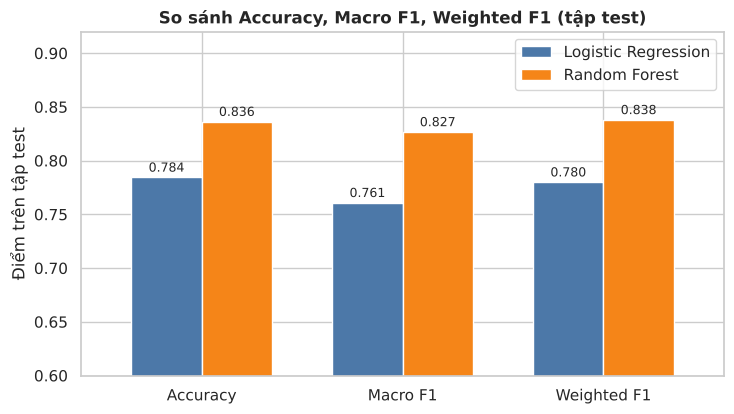


Precision / Recall / F1 theo từng nhãn:
            Mô hình         Nhãn  Precision  Recall    F1  Support
Logistic Regression      Healthy      0.850   0.857 0.854      687
Logistic Regression     Moderate      0.617   0.541 0.577      423
Logistic Regression Less Healthy      0.815   0.892 0.852      490
      Random Forest      Healthy      0.921   0.844 0.881      687
      Random Forest     Moderate      0.691   0.745 0.717      423
      Random Forest Less Healthy      0.862   0.904 0.882      490

F1 theo nhãn (dạng bảng so sánh):
Mô hình       Logistic Regression  Random Forest
Nhãn                                            
Healthy                     0.854          0.881
Moderate                    0.577          0.717
Less Healthy                0.852          0.882

Ma trận nhầm lẫn chuẩn hóa theo nhãn thật (% mỗi hàng):

Logistic Regression
              Healthy  Moderate  Less Healthy
Healthy          85.7      13.2           1.0
Moderate         24.1      54.1         

In [47]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

cmp_rows = []
for name in fitted:
    cmp_rows.append({"Mô hình": name,
                     "Accuracy": accuracy_score(y_test, preds[name]),
                     "Macro F1": f1_score(y_test, preds[name], average="macro"),
                     "Weighted F1": f1_score(y_test, preds[name], average="weighted")})
cmp_df = pd.DataFrame(cmp_rows).set_index("Mô hình")
print(cmp_df.round(3).to_string())
cmp_df.round(4).to_csv("model_comparison.csv", encoding="utf-8-sig")

# Biểu đồ cột nhóm
ax = cmp_df.T.plot(kind="bar", figsize=(7.5, 4.3), color=["#4c78a8", "#f58518"], width=0.7)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", padding=2, fontsize=9)
ax.set_ylim(0.6, 0.92)
ax.set_ylabel("Điểm trên tập test")
ax.set_title("So sánh Accuracy, Macro F1, Weighted F1 (tập test)", fontweight="bold")
plt.xticks(rotation=0)
plt.legend(title="")
plt.tight_layout()
plt.savefig("ml_model_comparison.png", dpi=120)
plt.show()

# F1, Precision, Recall theo từng nhãn
per_rows = []
for name in fitted:
    p, r, f, s = precision_recall_fscore_support(y_test, preds[name], labels=LABELS, zero_division=0)
    for i, lab in enumerate(LABELS):
        per_rows.append({"Mô hình": name, "Nhãn": lab, "Precision": p[i], "Recall": r[i], "F1": f[i], "Support": int(s[i])})
per_df = pd.DataFrame(per_rows)
print("\nPrecision / Recall / F1 theo từng nhãn:")
print(per_df.round(3).to_string(index=False))
per_df.round(4).to_csv("per_class_metrics.csv", index=False, encoding="utf-8-sig")

print("\nF1 theo nhãn (dạng bảng so sánh):")
print(per_df.pivot(index="Nhãn", columns="Mô hình", values="F1").reindex(LABELS).round(3).to_string())

# Moderate bị nhầm sang đâu? (tỷ lệ % theo hàng của ma trận nhầm lẫn)
print("\nMa trận nhầm lẫn chuẩn hóa theo nhãn thật (% mỗi hàng):")
for name in fitted:
    cm = confusion_matrix(y_test, preds[name], labels=LABELS)
    print(f"\n{name}")
    print((pd.DataFrame(cm, index=LABELS, columns=LABELS).div(cm.sum(axis=1), axis=0) * 100).round(1).to_string())
    print("Số lượng:"); print(pd.DataFrame(cm, index=LABELS, columns=LABELS).to_string())

**Nhận xét:**
- **Random Forest tốt hơn Logistic Regression ở cả ba chỉ số:** Accuracy 0,836 so với 0,784 (+0,052), Macro F1 0,827 so với 0,761 (+0,066), Weighted F1 0,838 so với 0,780 (+0,058). Chênh lệch Macro F1 lớn hơn Accuracy, nghĩa là Random Forest hơn rõ nhất ở lớp nhỏ và khó (Moderate).
- Macro F1 và Weighted F1 của Random Forest gần nhau (0,827 và 0,838), tức hiệu năng khá đồng đều giữa các lớp. Với Logistic Regression khoảng cách rộng hơn (0,761 so với 0,780) do lớp Moderate kéo Macro F1 xuống.

**Nhãn dự đoán chưa tốt: Moderate, ở cả hai mô hình.**
- F1 của Moderate: Random Forest **0,717**, Logistic Regression **0,577**; hai nhãn còn lại đều ở mức 0,85–0,88 (Random Forest 0,881 và 0,882; Logistic Regression 0,854 và 0,852).
- Logistic Regression chỉ nhận ra 54,1% sản phẩm Moderate (229/423); 24,1% bị đoán là Healthy và 21,7% bị đoán là Less Healthy. Random Forest nhận đúng 74,5% (315/423); phần sai là 11,8% sang Healthy và 13,7% sang Less Healthy.
- Với Random Forest, nhãn Moderate cũng là nhãn có precision thấp nhất (0,691): 94 sản phẩm Healthy và 47 Less Healthy bị đoán nhầm thành Moderate. Lỗi hầu hết xảy ra giữa các lớp kề nhau; Random Forest không đoán Less Healthy thành Healthy lần nào.
- Đây cũng chính là nhãn mà K-Means khớp kém nhất ở mục 7: Moderate là vùng chuyển tiếp, không có ranh giới tự nhiên trong dữ liệu. Vì vậy phần lớn lỗi là do bản chất nhãn trung gian chứ không hẳn do mô hình chọn sai.

**Kết luận:** chọn **Random Forest** làm mô hình chính. Hướng cải thiện Moderate là bổ sung đặc trưng gần với các ngưỡng tính điểm FSA hoặc điều chỉnh ngưỡng quyết định cho lớp này.

# Phần 5 – Kết luận cuối cùng của dự án
**Phân tích chất lượng dinh dưỡng và phân loại thực phẩm đóng gói – Open Food Facts**

Phần này tổng hợp kết quả từ các bước trước (làm sạch → EDA → chọn đặc trưng → mô hình → đánh giá) để trả lời các câu hỏi nghiên cứu RQ1–RQ7, nêu insight định lượng, khuyến nghị và hạn chế. Cần chạy các Phần 2, 05 và 06 trước để có các file `feature_dataset.csv`, `cv_results.csv`, `test_metrics.csv`, `best_model.csv`, `performance_by_category.csv`, `feature_importance.csv` (cùng `cleaned_dataset.csv` và `cleaning_report.csv` do bước làm sạch tạo ra) trong cùng thư mục.

## 1. Tóm tắt dự án

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
LABELS = ["Healthy", "Moderate", "Less Healthy"]

rep = pd.read_csv("cleaning_report.csv")
print(rep[["step", "rows_after", "removed"]].to_string(index=False))

data = pd.read_csv("feature_dataset.csv", dtype={"code": str})
cv_res = pd.read_csv("cv_results.csv")
test_res = pd.read_csv("test_metrics.csv")
bm = pd.read_csv("best_model.csv")
best = {"best_model": bm["best_model"].iloc[0], "auc": dict(zip(bm["class"], bm["auc"]))}
print("\nSố sản phẩm cuối:", len(data), "| danh mục:", data["main_category"].nunique(), "| quốc gia:", 5)

                                                    step  rows_after  removed
                                         Đọc dữ liệu thô       11301        0
             Bỏ mã vạch không phải số + bỏ trùng mã vạch       11301        0
            Bỏ mã vạch sai độ dài (< 8 hoặc > 14 chữ số)       10979      322
                         Bỏ sản phẩm không có tên hợp lệ       10775      204
                Giữ sản phẩm bán tại 5 quốc gia mục tiêu        8940     1835
                        Bỏ bản ghi có giá trị phi vật lý        8899       41
                   Bỏ bản ghi thiếu > 0 chỉ số trọng yếu        8103      796
Bỏ bản ghi năng lượng mâu thuẫn với thành phần (Atwater)        8054       49
Bỏ bản ghi trùng nội dung (cùng tên + hãng + dinh dưỡng)        7999       55

Số sản phẩm cuối: 7999 | danh mục: 4 | quốc gia: 5


**Quy trình:** dữ liệu thô 11.301 sản phẩm Open Food Facts (4 danh mục) → làm sạch còn **7.999 sản phẩm** thuộc 5 quốc gia (Pháp, Đức, Bỉ, Tây Ban Nha, Anh), đủ 6 chỉ số dinh dưỡng trọng yếu, đã loại giá trị phi vật lý và mâu thuẫn năng lượng → EDA → nhãn 3 mức theo ngưỡng FSA, độc lập Nutri-Score → Logistic Regression, Random Forest, K-Means.

## 2. Kết quả mô hình cuối cùng

                     CV_accuracy  CV_f1_macro  Accuracy  Precision_macro  Recall_macro  F1_macro  ROC_AUC_macro_ovr
mo_hinh                                                                                                            
Logistic Regression        0.794        0.774     0.784            0.761         0.764     0.761              0.908
Random Forest              0.836        0.827     0.836            0.824         0.831     0.827              0.950


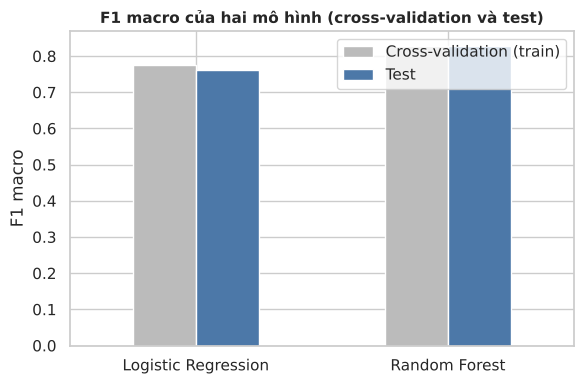

Mô hình chọn: Random Forest | AUC: {'Healthy': 0.969, 'Less Healthy': 0.979, 'Moderate': 0.902}
main_category     n  accuracy  f1_macro
    beverages 283.0     0.894     0.797
      dairies 443.0     0.916     0.891
        meals 433.0     0.755     0.609
       snacks 441.0     0.798     0.699


In [49]:
tab = cv_res.merge(test_res, on="mo_hinh").set_index("mo_hinh")
print(tab[["CV_accuracy", "CV_f1_macro", "Accuracy", "Precision_macro", "Recall_macro", "F1_macro", "ROC_AUC_macro_ovr"]].round(3))

fig, ax = plt.subplots(figsize=(6, 4))
piv = tab[["CV_f1_macro", "F1_macro"]].rename(columns={"CV_f1_macro": "Cross-validation (train)", "F1_macro": "Test"})
piv.plot(kind="bar", ax=ax, color=["#bbbbbb", "#4c78a8"], edgecolor="white")
ax.set_title("F1 macro của hai mô hình (cross-validation và test)", fontsize=11, fontweight="bold")
ax.set_ylabel("F1 macro")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("final_model_comparison.png", dpi=120)
plt.show()
print("Mô hình chọn:", best["best_model"], "| AUC:", {k: round(v, 3) for k, v in best["auc"].items()})
print(pd.read_csv("performance_by_category.csv").round(3).to_string(index=False))

**Kết quả chính:** **Random Forest** trên bộ đặc trưng đã chọn (không chứa 4 chất tạo nhãn) đạt **accuracy 83,6%, precision macro 0,824, recall macro 0,831, F1 macro 0,827** trên tập test, ROC-AUC macro 0,950 (từ 0,902 ở Moderate đến 0,979 ở Less Healthy). Logistic Regression thấp hơn ở mọi chỉ số (accuracy 78,4%, F1 macro 0,761; Weighted F1 0,780 so với 0,838 của Random Forest). Điểm cross-validation (F1 macro 0,827) trùng điểm test nên mô hình ổn định. Bộ đặc trưng cố ý loại 4 chất tạo nhãn để mô hình không chỉ học lại công thức tính nhãn.

**So sánh với phân cụm K-Means (Phần 4, mục 7):** K-Means không giám sát cho ARI = 0,431 và NMI = 0,398 so với nhãn FSA. Hai đầu khớp rõ (cụm năng lượng thấp: 87,2% Healthy; cụm năng lượng, đường cao: 77,3% Less Healthy), còn Moderate bị chia vào cả ba cụm. Nhãn Moderate cũng là nhãn cả hai mô hình dự đoán kém nhất (F1 0,717 với Random Forest, 0,577 với Logistic Regression).

## 3. Trả lời các câu hỏi nghiên cứu

### RQ1 – Phân bố dinh dưỡng giữa các danh mục

In [50]:
cols = ["energy-kcal_100g", "fat_100g", "sugars_100g", "salt_100g", "proteins_100g"]
print(data.groupby("main_category")[cols].median().round(2))
print()
print((pd.crosstab(data["main_category"], data["health_label"], normalize="index")[LABELS] * 100).round(1))

               energy-kcal_100g  fat_100g  sugars_100g  salt_100g  proteins_100g
main_category                                                                   
beverages                  39.0      0.01          4.1       0.02           0.22
dairies                   128.0      7.90          3.8       0.15           5.60
meals                     134.0      4.40          2.2       0.80           5.60
snacks                    473.0     22.00         23.0       0.51           7.00

health_label   Healthy  Moderate  Less Healthy
main_category                                 
beverages         80.5      14.4           5.2
dairies           41.1      19.4          39.5
meals             56.1      40.1           3.8
snacks             7.7      27.7          64.7


**Trả lời:** có sự khác biệt rất lớn và có ý nghĩa thống kê (Kruskal–Wallis, p < 0,001 cho mọi chỉ số, ở Phần 1 (EDA)). Snacks có năng lượng trung vị 473 kcal và 64,7% thuộc Less Healthy; dairies nhiều béo bão hòa (39,5% Less Healthy); meals muối cao nhất nhưng chỉ 3,8% Less Healthy; beverages 80,5% Healthy nhưng đường lỏng là điểm yếu.

### RQ2 – Tương quan đường, béo bão hòa, năng lượng

**Trả lời:** năng lượng tương quan mạnh với béo bão hòa (Spearman 0,77) và béo (0,88), yếu hơn với đường (0,29). Béo và béo bão hòa gần như trùng nhau (0,91), còn đường gần độc lập với béo (0,12): đường và béo là hai con đường riêng làm sản phẩm kém lành mạnh. Chiều tương quan đường–năng lượng đổi dấu theo danh mục (beverages +0,68, dairies −0,56), nên cần phân tích theo từng nhóm.

### RQ3 – Nutri-Score tốt giữa các quốc gia

In [51]:
s = data.dropna(subset=["country_single"])
print("Số sản phẩm bán ở đúng 1 nước:", len(s))
print((pd.crosstab(s["country_single"], s["health_label"], normalize="index")[LABELS] * 100).round(1))
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(s["country_single"], s["health_label"]))
print(f"\nChi-square nhãn FSA theo nước: chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2g}")

Số sản phẩm bán ở đúng 1 nước: 4685
health_label    Healthy  Moderate  Less Healthy
country_single                                 
belgium            46.6      29.6          23.8
france             44.7      25.6          29.7
germany            41.8      27.4          30.8
spain              47.9      31.1          21.0
united-kingdom     50.7      30.3          18.9

Chi-square nhãn FSA theo nước: chi2 = 58.1, dof = 8, p = 1.1e-09


**Trả lời:** tỷ lệ Nutri-Score A/B (EDA) cao nhất ở Anh (33,1%) và Pháp (31,2%), thấp nhất ở Đức và Bỉ (≈24,5%). Dùng nhãn FSA của nhóm, Anh vẫn đứng đầu (50,7% Healthy) nhưng Tây Ban Nha và Bỉ lại cao hơn Pháp và Đức. Vì thứ tự giữa các nước **không ổn định giữa hai cách chấm**, và chênh lệch chỉ khoảng 9 điểm phần trăm giữa nước cao nhất và thấp nhất, kết luận an toàn là: khác biệt có ý nghĩa thống kê (p rất nhỏ do mẫu lớn) nhưng nhỏ, và chịu ảnh hưởng của cơ cấu danh mục từng nước; chưa đủ cơ sở nói nước nào "lành mạnh hơn".

### RQ4 – Yếu tố quan trọng nhất

In [52]:
print(pd.read_csv("feature_importance.csv").round(4).to_string(index=False))

           dac_trung  giam_F1    std
    energy-kcal_100g   0.4538 0.0108
       main_category   0.1161 0.0066
          fiber_100g   0.0353 0.0034
protein_energy_share   0.0296 0.0050
       proteins_100g   0.0239 0.0041
         additives_n   0.0205 0.0039
           has_fiber   0.0025 0.0015


**Trả lời:** **mật độ năng lượng** là yếu tố quan trọng nhất (xáo trộn làm F1 giảm 0,45, gần 4 lần biến kế tiếp), sau đó là **danh mục sản phẩm** (0,116), chất xơ (0,035), % năng lượng từ đạm (0,030), đạm (0,024), phụ gia (0,021). Ở EDA, điểm Nutri-Score cũng liên quan mạnh nhất với năng lượng (0,71), béo bão hòa (0,68), béo (0,67).

### RQ5 – Dự đoán cho sản phẩm thiếu nhãn

**Trả lời:** **có, ở mức khá tốt.** Trên tập test (1.600 sản phẩm không tham gia huấn luyện), mô hình dự đoán nhãn FSA đúng 83,6% (F1 macro 0,827) mà không dùng 4 chất tạo nhãn. Less Healthy và Healthy được nhận ra tốt (F1 0,882 và 0,881), Moderate yếu hơn (0,717) và lỗi chủ yếu xảy ra giữa hai lớp kề nhau (chỉ 13/687 Healthy bị đoán thành Less Healthy). Mô hình khớp Nutri-Score gộp 65,4%, tương đương mức khớp giữa nhãn FSA và Nutri-Score (67,3%), nên không nên xem là thay thế Nutri-Score.

### RQ6 – NOVA và phụ gia

In [53]:
k = data.dropna(subset=["nova_group"])
print((pd.crosstab(k["nova_group"], k["health_label"], normalize="index")[LABELS] * 100).round(1))
print()
print(k.groupby("nova_group")["additives_n"].agg(["count", "mean", "median"]).round(2))

health_label  Healthy  Moderate  Less Healthy
nova_group                                   
1.0              79.0      14.6           6.4
2.0               0.8       0.0          99.2
3.0              38.8      26.2          35.0
4.0              38.9      28.8          32.3

            count  mean  median
nova_group                     
1.0           603  0.04     0.0
2.0           113  0.00     0.0
3.0          1925  0.25     0.0
4.0          4522  2.54     2.0


**Trả lời:** phụ gia tăng rõ theo mức chế biến: trung bình 0,04 (NOVA 1), 0 (NOVA 2), 0,25 (NOVA 3) và 2,54 (NOVA 4); Spearman 0,65, Kruskal–Wallis p ≈ 0 (EDA). Tuy nhiên mối liên hệ này một phần mang tính định nghĩa vì phụ gia là dấu hiệu để xếp NOVA 4. Điều thú vị: NOVA 1 có 79,0% Healthy theo FSA, nhưng NOVA 3 (38,8%) và NOVA 4 (38,9%) gần như **không khác nhau** về tỷ lệ Healthy. Tức là mức độ chế biến cao không đồng nghĩa với nhiều béo, đường, muối hơn, và hai thước đo (NOVA và nhãn dinh dưỡng) bổ sung cho nhau. NOVA 2 (chỉ 113 sản phẩm, như dầu, đường, bơ) gần như toàn Less Healthy (99,2%) nên cần thận trọng khi diễn giải.

### RQ7 – Khuyến nghị

In [54]:
cols = ["energy-kcal_100g", "fat_100g", "saturated-fat_100g", "sugars_100g", "salt_100g"]
ref = pd.read_csv("cleaned_dataset.csv", dtype={"code": str})[["code", "saturated-fat_100g"]]
tmp = data.drop(columns=[c for c in ["saturated-fat_100g"] if c in data.columns]).merge(ref, on="code", how="left")
print("Trung vị mỗi chỉ số theo nhãn (trên 100g):")
print(tmp.groupby("health_label")[cols].median().reindex(LABELS).round(2).T)

Trung vị mỗi chỉ số theo nhãn (trên 100g):
health_label        Healthy  Moderate  Less Healthy
energy-kcal_100g      57.00    213.01        464.00
fat_100g               1.40      8.00         25.00
saturated-fat_100g     0.30      2.50         14.00
sugars_100g            3.30      3.60         12.00
salt_100g              0.13      0.74          0.65


**Trả lời:** xem mục 5 bên dưới.

## 4. Năm insight định lượng
1. **Snacks là nhóm rủi ro nhất:** 64,7% thuộc Less Healthy (so với 3,8% ở meals và 5,2% ở beverages); năng lượng trung vị 473 kcal/100g; 78,2% là siêu chế biến; 49,2% Nutri-Score E.
2. **Dairies bị đánh giá thấp chủ yếu vì béo bão hòa:** 39,5% thuộc Less Healthy, và trong nhóm này 99% vượt ngưỡng béo bão hòa nhưng chỉ 2% vượt ngưỡng đường.
3. **Snacks kém vì cả béo lẫn đường:** trong số snacks Less Healthy, 87% vượt ngưỡng béo, 79% béo bão hòa, 69% đường; chỉ 11% vượt ngưỡng muối.
4. **Meals cần chú ý muối:** meals có muối trung vị cao nhất (0,8 g/100g), và trong nhóm meals Less Healthy (chỉ 83 sản phẩm), 72% vượt ngưỡng muối.
5. **Mật độ năng lượng là tín hiệu mạnh nhất:** sản phẩm Healthy có năng lượng trung vị 57 kcal/100g, Moderate 213, Less Healthy 464 kcal/100g; chỉ cần năng lượng, đạm, chất xơ, phụ gia và danh mục đã dự đoán đúng 83,6% nhãn.

## 5. Khuyến nghị
**Cho người tiêu dùng**
- Xem nhanh **năng lượng trên 100g**: dưới khoảng 60 kcal thường thuộc nhóm Healthy, còn nhóm Less Healthy có trung vị 464 kcal (trung vị Healthy là 57 kcal).
- **Snacks:** ưu tiên sản phẩm dưới 22,5 g đường, dưới 17,5 g béo và dưới 5 g béo bão hòa trên 100g (ngưỡng "cao" của FSA). Khoảng một nửa số snacks vượt từng ngưỡng đường (50,8%) hoặc béo bão hòa (53,0%).
- **Sữa và chế phẩm:** chọn loại ít béo bão hòa (dưới 5 g/100g); đường không phải vấn đề chính ở nhóm này.
- **Món ăn chế biến sẵn, súp, nước sốt:** đọc nhãn muối, giữ dưới 1,5 g/100g (đồ uống dưới 0,75 g/100ml).
- **Đồ uống:** chọn loại dưới 2,5 g đường/100ml (ngưỡng thấp); vẫn có 9,4% đồ uống vượt ngưỡng đường cao.
- Đừng chỉ dùng mức độ chế biến (NOVA) để đánh giá: NOVA 3 và 4 có tỷ lệ Healthy gần như bằng nhau; nên kết hợp với nhãn dinh dưỡng.

**Cho doanh nghiệp**
- Snacks: giảm đồng thời béo bão hòa và đường, vì đa số sản phẩm Less Healthy vượt cả hai ngưỡng.
- Dairies: giảm béo bão hòa (đổi công thức, sản phẩm ít béo) là đòn bẩy lớn nhất.
- Meals: giảm muối.
- Công bố đầy đủ chất xơ và Nutri-Score: 30,6% sản phẩm thiếu chất xơ và 4,9% thiếu Nutri-Score, làm giảm khả năng so sánh trên thị trường.

## 6. Hạn chế và hướng phát triển
- **Nhãn là nhãn tự xây:** dựa trên 4 chất theo ngưỡng FSA, không tính đạm, chất xơ, rau quả như Nutri-Score; mô hình dự đoán nhãn này chứ không phải "độ lành mạnh" tuyệt đối. Quy tắc gán nhãn (Healthy: không ô đỏ và tổng điểm ≤ 2; Less Healthy: từ 2 ô đỏ trở lên hoặc tổng điểm ≥ 5; còn lại là Moderate) là lựa chọn của nhóm.
- **Rò rỉ gián tiếp:** năng lượng được tính từ béo, đường, đạm nên bộ đặc trưng vẫn mang thông tin gián tiếp về nhãn. Kết quả 83,6% nên hiểu là "dự đoán chất lượng từ năng lượng, đạm, chất xơ, phụ gia, danh mục", không phải dự đoán từ tên hay hình ảnh sản phẩm.
- **Dữ liệu cộng đồng:** thiên lệch theo nước, hãng và độ phủ nhập liệu; hạng và điểm Nutri-Score đôi khi không khớp (lẫn cách tính cũ và mới); 41% sản phẩm bán ở nhiều nước nên so sánh quốc gia chỉ dùng được nhóm bán ở một nước.
- **Mô hình:** chưa tinh chỉnh siêu tham số kỹ; lớp Moderate còn yếu (F1 0,717, và là lớp K-Means cũng khớp kém nhất với nhãn); meals (F1 0,609) và snacks (0,699) thấp hơn dairies (0,891).
- **Hướng phát triển:** thử Gradient Boosting và tinh chỉnh siêu tham số; thêm thành phần (danh sách nguyên liệu) vào đặc trưng; kiểm chứng ngoài mẫu bằng dữ liệu nước khác; chia train/test theo thương hiệu để kiểm tra khả năng tổng quát hóa; thử quy tắc nhãn khác (ví dụ chỉ dùng tổng điểm FSA với ngưỡng 2 và 4 điểm) và so sánh lại bằng ARI/NMI với K-Means.